# 05 — Pattern Discovery & Validation

**Goal (RQ1):** turn the feature clusters (FCs) from NB04 into evidence for expert verification with Wiener Linien, and prepare the hand-over to RQ2 (subsystem-specific datasets).

This notebook:
1. scores every FC as a failure detector at **event level**: early hits, false-alarm episodes, lead time (Helm 2025, p96; Steiner et al., RAMS 2026, p6),
2. zooms into the **intervals flagged by the prior-work models** (RF and LSTM-AE from NB02b) and asks which FCs sit behind true early hits and which behind false alarms. This is the pipeline proposed in RAMS 2026 (p7) and the "predefined MetroAT anomaly windows" of the proposal,
3. relates FCs to the **failure types recorded by Wiener Linien**,
4. exports an **expert verification sheet** and the code that turns the filled sheet into subsystem datasets.

**Neutral presentation:** FCs are labelled FC1, FC2, … and described only by their sensors. Subsystem assignment is part of the expert verification (Presentation, slide 11).

**Train/test separation:** NB04 forms the FCs on train-period windows only, and the KEEP/REVIEW verdict below is decided on the 10 train events only. The 11 test events are used only to check whether a verdict holds on unseen data, so the test period stays an unbiased evaluation set for RQ2.

**Pipeline:** NB01 → NB02a → NB02b → NB03 → **NB04** (feature clustering) → **NB05** (pattern discovery & validation)

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
import seaborn as sns
from scipy.stats import fisher_exact
warnings.filterwarnings('ignore')

ROOT = os.path.abspath('..')
OUT = os.path.join(ROOT, 'outputs')
A = os.path.join(OUT, 'nb04_artifacts')
NB05_OUT = os.path.join(OUT, 'nb05_artifacts')
os.makedirs(NB05_OUT, exist_ok=True)

all_sup = pd.read_parquet(os.path.join(A, 'all_sup.parquet'))
all_sup['window_end'] = pd.to_datetime(all_sup['window_end'])
anom_activations = pd.read_parquet(os.path.join(A, 'anom_activations.parquet'))
anom_meta = pd.read_parquet(os.path.join(A, 'anom_meta.parquet'))
anom_orig_idx = np.load(os.path.join(A, 'anom_orig_idx.npy'))
anom_activations.index = pd.Index(anom_orig_idx)
anom_meta.index = pd.Index(anom_orig_idx)

fail_events = pd.read_parquet(os.path.join(A, 'fail_events.parquet'))
fc_temporal = pd.read_csv(os.path.join(A, 'fc_temporal.csv'))
fc_variance = pd.read_csv(os.path.join(A, 'fc_variance.csv'))
fc_location = pd.read_csv(os.path.join(A, 'fc_location.csv'))
fc_drift = pd.read_csv(os.path.join(A, 'fc_drift.csv'))
with open(os.path.join(A, 'heuristic_a.json')) as f:
    clusters = {int(k): v for k, v in json.load(f).items()}
with open(os.path.join(A, 'feature_cols.json')) as f:
    feature_cols = json.load(f)
with open(os.path.join(A, 'constants.json')) as f:
    constants = json.load(f)

SPLIT_DATE = pd.Timestamp(constants['SPLIT_DATE'])
HORIZON_S = constants['HORIZON_S']
WINDOW_S = constants['WINDOW_S']
fc_ids = sorted(clusters.keys())

# FC activation on every window (False for non-anomalous windows)
fc_act_all = pd.DataFrame(False, index=all_sup.index, columns=fc_ids)
for fc in fc_ids:
    fc_act_all.loc[anom_orig_idx, fc] = anom_activations[clusters[fc]].any(axis=1).values

print(f'Windows: {len(all_sup):,} | anomalous: {len(anom_activations):,} | FCs: {len(clusters)} '
      f'({sum(len(v) for v in clusters.values())} features)')
print(f'Canonical failure events (from NB04): {len(fail_events)} '
      f'(train {(fail_events.split == "train").sum()}, test {(fail_events.split == "test").sum()})')

Windows: 64,522 | anomalous: 12,022 | FCs: 19 (126 features)
Canonical failure events (from NB04): 21 (train 10, test 11)


## 1. FC Overview: Size, Sensors & Activation Rates

For each FC: how many features and sensors, how often it fires in anomalous windows, and the failure-label rate among those windows.

In [2]:
def sensor_name(f):
    parts = f.rsplit('_', 1)
    return parts[0] if parts[-1] in ('min', 'max', 'mean', 'std', 'flips', 's') else f


rows = []
for fc in fc_ids:
    feats = clusters[fc]
    act = anom_activations[feats].any(axis=1)
    sensors = sorted({sensor_name(f).replace('_active', '') for f in feats})
    rows.append({'FC': f'FC{fc}', 'fc_id': fc, 'n_features': len(feats), 'n_sensors': len(sensors),
                 'activation_rate': act.mean(), 'n_active_windows': int(act.sum()),
                 'failure_rate': anom_meta.loc[act, 'label'].mean(),
                 'sensors': ', '.join(sensors[:3]) + ('...' if len(sensors) > 3 else '')})
fc_summary = pd.DataFrame(rows)
print(fc_summary.drop(columns='fc_id').round(3).to_string(index=False))

  FC  n_features  n_sensors  activation_rate  n_active_windows  failure_rate                                                                                                           sensors
 FC1          12         12            0.232              2794         0.048     CW1_BRAKE_CYLINDER_PRESSURE_BOGIE1, CW1_BRAKE_CYLINDER_PRESSURE_BOGIE2, CW2_BRAKE_CYLINDER_PRESSURE_BOGIE1...
 FC2           1          1            0.326              3925         0.101                                                                                                   MW4_LOAD_SIGNAL
 FC3           4          4            0.056               679         0.106                 CW1_SPRING_BRAKE_ACTIVE_BOGIE1, CW1_SPRING_BRAKE_ACTIVE_BOGIE2, CW2_SPRING_BRAKE_ACTIVE_BOGIE1...
 FC4           1          1            0.041               490         0.078                                                                                            CW1_COMPRESSOR_RUNNING
 FC5           1          1            0.029 

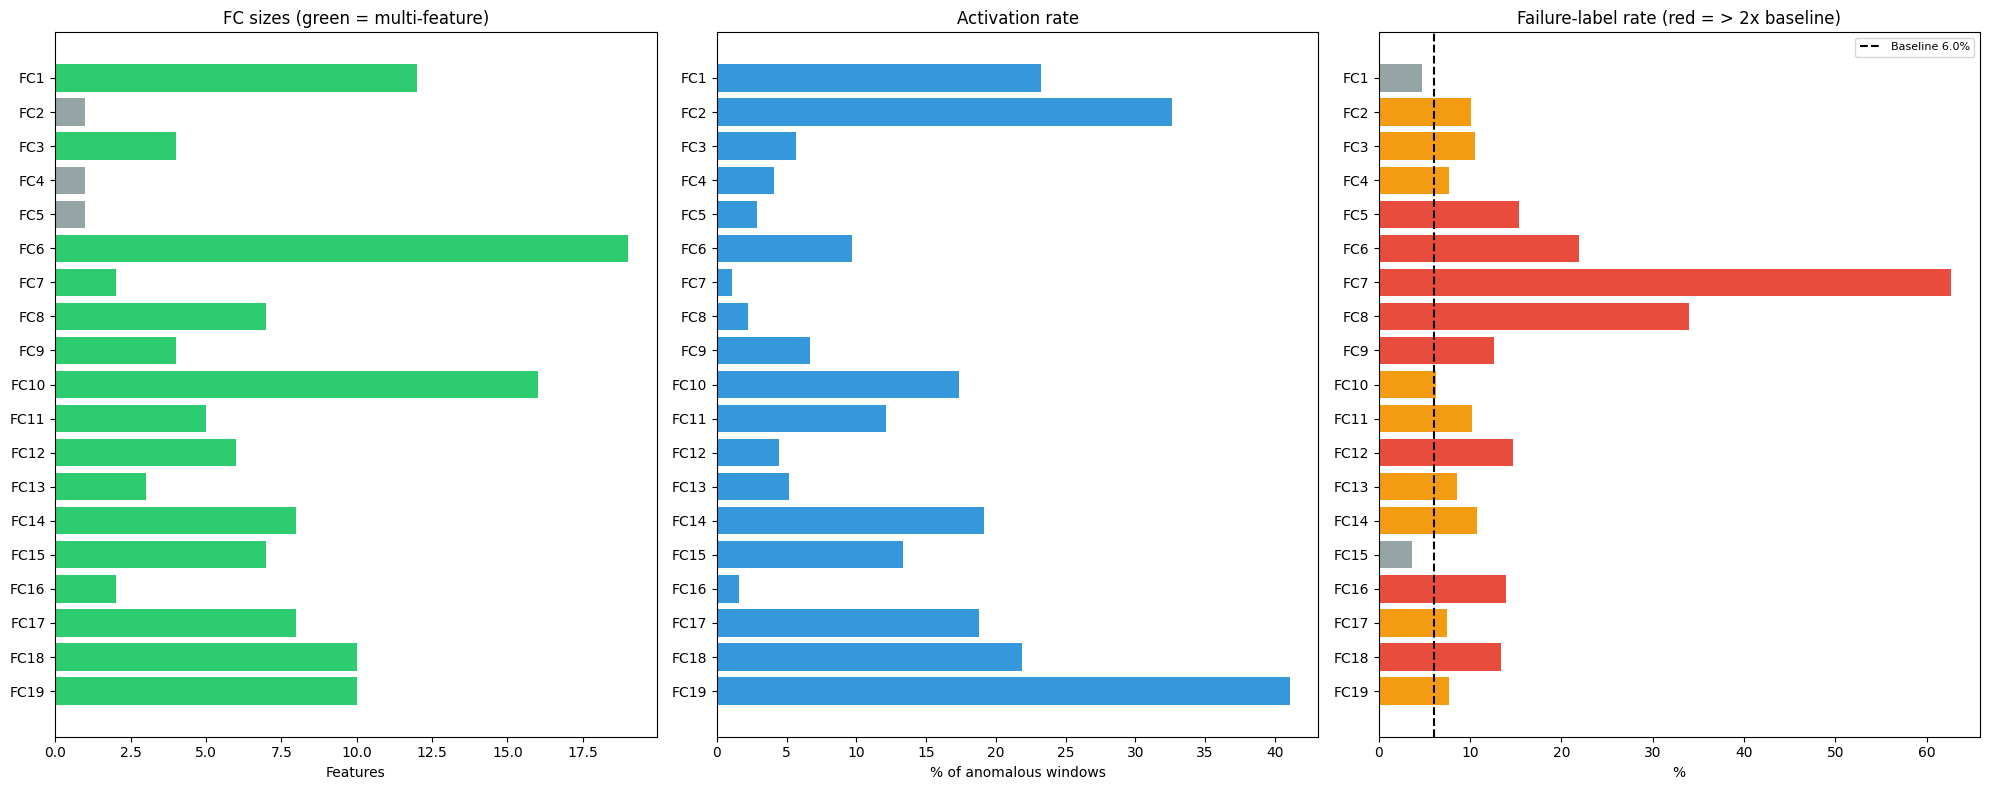

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(20, 8))
labels = fc_summary['FC']
axes[0].barh(labels, fc_summary['n_features'], color=['#2ecc71' if n > 1 else '#95a5a6' for n in fc_summary['n_features']])
axes[0].set_title('FC sizes (green = multi-feature)'); axes[0].set_xlabel('Features')
axes[1].barh(labels, 100 * fc_summary['activation_rate'], color='#3498db')
axes[1].set_title('Activation rate'); axes[1].set_xlabel('% of anomalous windows')
baseline = anom_meta['label'].mean()
fr = fc_summary['failure_rate']
axes[2].barh(labels, 100 * fr, color=['#e74c3c' if v > 2 * baseline else '#f39c12' if v > baseline else '#95a5a6' for v in fr])
axes[2].axvline(100 * baseline, color='black', ls='--', label=f'Baseline {100*baseline:.1f}%')
axes[2].set_title('Failure-label rate (red = > 2x baseline)'); axes[2].set_xlabel('%'); axes[2].legend(fontsize=8)
for ax in axes:
    ax.invert_yaxis()
plt.tight_layout()
plt.savefig(os.path.join(NB05_OUT, 'fc_overview.png'), dpi=150, bbox_inches='tight')
plt.show()

In [4]:
# Full feature list and sensor location per FC (for expert review)
loc = fc_location.set_index('FC')
for fc in fc_ids:
    l = loc.loc[f'FC{fc}']
    print(f'\nFC{fc} ({len(clusters[fc])} features | cars: {l.cars} | side A/B: {l.side_A_share:.0%}/{l.side_B_share:.0%} | bogies: {l.bogies})')
    for f in sorted(clusters[fc]):
        print(f'  {f}')


FC1 (12 features | cars: CW1, CW2, MW1, MW2, MW3, MW4 | side A/B: 50%/50% | bogies: B1, B2)
  CW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_min
  CW1_BRAKE_CYLINDER_PRESSURE_BOGIE2_min
  CW2_BRAKE_CYLINDER_PRESSURE_BOGIE1_min
  CW2_BRAKE_CYLINDER_PRESSURE_BOGIE2_min
  MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_min
  MW1_BRAKE_CYLINDER_PRESSURE_BOGIE2_min
  MW2_BRAKE_CYLINDER_PRESSURE_BOGIE1_min
  MW2_BRAKE_CYLINDER_PRESSURE_BOGIE2_min
  MW3_BRAKE_CYLINDER_PRESSURE_BOGIE1_min
  MW3_BRAKE_CYLINDER_PRESSURE_BOGIE2_min
  MW4_BRAKE_CYLINDER_PRESSURE_BOGIE1_min
  MW4_BRAKE_CYLINDER_PRESSURE_BOGIE2_min

FC2 (1 features | cars: MW4 | side A/B: 0%/100% | bogies: -)
  MW4_LOAD_SIGNAL_min

FC3 (4 features | cars: CW1, CW2 | side A/B: 50%/50% | bogies: B1, B2)
  CW1_SPRING_BRAKE_ACTIVE_BOGIE1_flips
  CW1_SPRING_BRAKE_ACTIVE_BOGIE2_flips
  CW2_SPRING_BRAKE_ACTIVE_BOGIE1_flips
  CW2_SPRING_BRAKE_ACTIVE_BOGIE2_flips

FC4 (1 features | cars: CW1 | side A/B: 100%/0% | bogies: -)
  CW1_COMPRESSOR_RUNNING_flips

FC5 (1 fe

## 2. Failure Events and Window Phases

Failure events come from NB04's canonical table (raw `TRAIN_IS_IN_FAILURE` flag, same-type blocks less than 1 h apart merged). Every window carries a **phase**: early (6 days to 1 day before onset), imminent (last 24 h), during, normal (more than 7 days before and more than 24 h after a failure), plus buffer/post.

The supervised label of NB02a (`label = 1`) covers exactly the last 6.2 h before onset plus the failure itself, so it is **not** an early-warning signal on its own. The early window is what matters for prediction.

In [5]:
display(fail_events)
print('\nFailure types (Wiener Linien records):', fail_events['event_type'].value_counts().to_dict())

all_sup['in_label_horizon'] = (all_sup['ev_offset_h'] >= -HORIZON_S / 3600) & (all_sup['ev_offset_h'] < 0)
tab = pd.crosstab(all_sup['phase'], all_sup['label'], margins=True)
print('\nWindows by phase and NB02a label:')
print(tab.to_string())
anom_phase = all_sup.loc[anom_orig_idx, 'phase'].value_counts()
print('\nAnomalous windows by phase:')
print(anom_phase.to_string())

,start,end,event_type,duration_h,split
event_id,,,,,
1,2024-06-27 15:47:30,2024-06-27 17:52:28,Brake System Failure,2.082778,train
2,2024-08-19 10:37:51,2024-08-19 11:05:44,Brake System Failure,0.464722,train
3,2024-08-27 15:58:43,2024-08-28 21:29:25,Leveling System Failure,29.511667,train
4,2024-09-03 05:04:00,2024-09-03 07:33:36,Brake System Failure,2.493333,train
5,2024-09-22 05:49:43,2024-09-22 08:14:45,Brake System Failure,2.417222,train
6,2024-10-06 02:04:15,2024-10-08 09:15:36,Brake System Failure,55.189167,train
7,2024-10-10 11:19:48,2024-10-10 15:35:49,Brake System Failure,4.266944,train
8,2024-10-31 15:08:06,2024-10-31 18:26:02,Compressor Module Failure,3.298889,train
9,2024-12-14 18:56:40,2024-12-14 23:31:05,Brake System Failure,4.573611,train



Failure types (Wiener Linien records): {'Brake System Failure': 13, 'Compressor Module Failure': 6, 'Leveling System Failure': 2}

Windows by phase and NB02a label:
label         0     1    All
phase                       
buffer     2299     0   2299
during        0   543    543
early     14179     0  14179
imminent   2344   659   3003
normal    42377     0  42377
post       2121     0   2121
All       63320  1202  64522

Anomalous windows by phase:
phase
normal      6466
early       2997
imminent    1103
post         682
during       403
buffer       371


In [6]:
# FC phase enrichment and lead time (computed in NB04 §4.3) + volatility lead-up (NB04 §4.5)
print('Temporal pattern per FC (NB04 §4.3):')
print(fc_temporal.drop(columns='fc_id').round(2).to_string(index=False))
print('\nVolatility lead-up (NB04 §4.5):')
print(fc_variance.round(3).to_string(index=False))

Temporal pattern per FC (NB04 §4.3):
  FC  normal_rate_train_%  normal_rate_test_%  early_rate_%  imminent_rate_%  during_rate_%  enrich_early  enrich_imminent  enrich_during  events_early  expected_early  p_early  events_24h  expected_24h  p_24h  events_during  expected_during  p_during  median_lead_24h_h              pattern
 FC1                 4.12                3.06          4.85             4.36          15.65          1.37             1.23           4.28            20           20.08     0.91          14         17.78   1.00             14             9.83      0.02              13.85       detection-only
 FC2                 3.70                6.26          7.26             8.66          58.75          1.42             1.71          12.22            20           20.16     0.99          14         17.91   1.00             14            11.56      0.13              13.96         weak / mixed
 FC3                 0.27                2.36          1.32             2.30           

## 3. Event-Level Scoring of Each FC as a Failure Detector

Each FC is treated as a detector. Following Helm (2025, p91–97) and Steiner et al. (RAMS 2026, p6):

- **Alarm episodes:** FC-active windows less than 30 min apart are merged into one episode. Only episodes with at least 2 windows count as alarms (a persistence filter against single-window noise). Results without the filter are also reported.
- **Early hit:** an alarm episode overlapping the early window [−6 d, −1 d] of an event.
- **Late hit:** an alarm overlapping [−24 h, end] but not the early window.
- **False alarm:** an alarm overlapping no event window. Alarms within 24 h after a failure are counted separately as post-failure.
- **Lift:** alarms near events divided by the number expected if alarms fell at random in time, computed within each period (train/test) to control for the test-period drift. A lift of 1 means chance level.
- **Lead time:** hours between the first alarm in the 24 h before onset and the onset (Helm's 24 h look-back, 2025, p83–84). Reported as the median over events with such an alarm.

The FAR, detection rate and detection delay correspond to the evaluation vocabulary of the SaECCA paper (IEEE TII 2025, Yin Shen collection).

**Verdict (train events only):** **KEEP** if, on the **10 train events**, lift ≥ 1.5 and at least 3 events are covered (early or late). Otherwise **REVIEW**, meaning expert input is needed. The test period is not used for the verdict, so features chosen for RQ2 are not selected on the data they are evaluated on.

**Test check:** the same rule is applied to the **11 test events** (`test_check` = holds / fails). A KEEP FC that fails the check is a candidate for drift or overfitting to the train period. A drift flag from NB04 §4.6 is attached.

Lift, events covered and the other columns without a suffix are computed over all 21 events and are reported as descriptive evidence only.

In [7]:
GAP = pd.Timedelta(minutes=30)
starts = fail_events['start']
ends = fail_events['end']


def make_episodes(times, gap):
    t = pd.Series(np.sort(pd.to_datetime(times).values))
    if t.empty:
        return pd.DataFrame(columns=['start', 'end', 'n'])
    gid = (t.diff() > gap).cumsum()
    return t.groupby(gid).agg(start='min', end='max', n='size').reset_index(drop=True)


def classify_episode(s, e):
    early = [i for i in fail_events.index if s <= starts[i] - pd.Timedelta(days=1) and e >= starts[i] - pd.Timedelta(days=6)]
    late = [i for i in fail_events.index if i not in early and s <= ends[i] and e >= starts[i] - pd.Timedelta(days=1)]
    post = [i for i in fail_events.index if s <= ends[i] + pd.Timedelta(hours=24) and e >= ends[i]]
    kind = 'early_hit' if early else 'late_hit' if late else 'post_failure' if post else 'false_alarm'
    return kind, early, late


def score_episodes(eps):
    out = eps.copy()
    res = [classify_episode(r.start, r.end) for r in eps.itertuples()]
    out['kind'] = [r[0] for r in res]
    out['early_events'] = [r[1] for r in res]
    out['late_events'] = [r[2] for r in res]
    return out


near = all_sup['phase'].isin(['early', 'imminent', 'during'])
chance = {sp: near[all_sup['split'] == sp].mean() for sp in ('train', 'test')}
normal_days = (all_sup['phase'] == 'normal').sum() * WINDOW_S / 86400
n_ev = len(fail_events)
print(f'Share of windows near an event (chance level for lift): train {chance["train"]:.1%}, test {chance["test"]:.1%}; '
      f'normal time: {normal_days:.0f} days\n')

score_rows, fc_episodes = [], {}
for fc in fc_ids:
    eps_all = score_episodes(make_episodes(all_sup.loc[fc_act_all[fc], 'window_end'], GAP))
    eps = eps_all[eps_all['n'] >= 2].reset_index(drop=True)
    fc_episodes[fc] = eps
    early_ev = sorted({e for l in eps['early_events'] for e in l})
    late_ev = sorted({e for l in eps['late_events'] for e in l} - set(early_ev))
    n_alarm = len(eps)
    n_near = int(eps['kind'].isin(['early_hit', 'late_hit']).sum())
    n_fa = int((eps['kind'] == 'false_alarm').sum())
    precision = n_near / n_alarm if n_alarm else np.nan
    leads = []
    for ev in fail_events.index:
        pre = eps[(eps['end'] >= starts[ev] - pd.Timedelta(hours=24)) & (eps['start'] < starts[ev])]
        if len(pre):
            leads.append(max((starts[ev] - pre['start'].min()).total_seconds() / 3600, 0))
    covered = len(early_ev) + len(late_ev)
    alarm_split = np.where(eps['start'] < SPLIT_DATE, 'train', 'test') if n_alarm else np.array([])
    expected_near = sum((alarm_split == sp).sum() * chance[sp] for sp in chance)
    lift = n_near / expected_near if expected_near > 0 else np.nan
    # Same lift and coverage per period: the verdict uses train only, test is the check
    is_near = eps['kind'].isin(['early_hit', 'late_hit']).values if n_alarm else np.array([], dtype=bool)
    per_split = {}
    for sp in ('train', 'test'):
        n_sp = int((alarm_split == sp).sum())
        exp_sp = n_sp * chance[sp]
        cov_sp = sum(fail_events.loc[e, 'split'] == sp for e in early_ev + late_ev)
        per_split[sp] = (int(is_near[alarm_split == sp].sum()) / exp_sp if exp_sp > 0 else np.nan, cov_sp)
    score_rows.append({
        'FC': f'FC{fc}', 'fc_id': fc, 'alarms': n_alarm, 'alarms_no_filter': len(eps_all),
        'early_hits': len(early_ev), 'late_hits': len(late_ev), 'events_covered': covered,
        'early_hits_train': sum(fail_events.loc[e, 'split'] == 'train' for e in early_ev),
        'early_hits_test': sum(fail_events.loc[e, 'split'] == 'test' for e in early_ev),
        'false_alarms': n_fa, 'fa_per_30_normal_days': 30 * n_fa / normal_days,
        'false_alarms_no_filter': int((eps_all['kind'] == 'false_alarm').sum()),
        'event_precision': precision, 'lift': lift,
        'median_lead_h': np.median(leads) if leads else np.nan,
        'lift_train': per_split['train'][0], 'events_covered_train': per_split['train'][1],
        'lift_test': per_split['test'][0], 'events_covered_test': per_split['test'][1],
        'verdict': 'KEEP' if (per_split['train'][0] >= 1.5 and per_split['train'][1] >= 3) else 'REVIEW',
        'test_check': 'holds' if (per_split['test'][0] >= 1.5 and per_split['test'][1] >= 3) else 'fails'})

fc_scores = pd.DataFrame(score_rows).merge(fc_drift[['FC', 'drift_flag']], on='FC', how='left')
fc_scores = fc_scores.merge(fc_temporal[['FC', 'pattern']], on='FC', how='left')
cols = ['FC', 'alarms', 'early_hits', 'late_hits', 'events_covered', 'false_alarms', 'fa_per_30_normal_days',
        'event_precision', 'median_lead_h', 'pattern', 'drift_flag',
        'lift_train', 'events_covered_train', 'verdict', 'lift_test', 'events_covered_test', 'test_check']
print(f'Events: {n_ev} (train {(fail_events.split == "train").sum()}, test {(fail_events.split == "test").sum()})\n')
print(fc_scores[cols].round(2).to_string(index=False))
print(f'\nKEEP (train events): {(fc_scores.verdict == "KEEP").sum()} | REVIEW: {(fc_scores.verdict == "REVIEW").sum()}')
keep_fc = fc_scores[fc_scores.verdict == 'KEEP']
print(f'Test check of the KEEP FCs: {(keep_fc.test_check == "holds").sum()}/{len(keep_fc)} hold on the 11 test events')
print(f'False alarms with vs without persistence filter (sum over FCs): '
      f'{fc_scores.false_alarms.sum()} vs {fc_scores.false_alarms_no_filter.sum()}')

Share of windows near an event (chance level for lift): train 19.4%, test 41.9%; normal time: 172 days



Events: 21 (train 10, test 11)

  FC  alarms  early_hits  late_hits  events_covered  false_alarms  fa_per_30_normal_days  event_precision  median_lead_h              pattern  drift_flag  lift_train  events_covered_train verdict  lift_test  events_covered_test test_check
 FC1     673          20          0              20           421                  73.57             0.32          11.67       detection-only       False        1.22                     9  REVIEW       1.18                   11      fails
 FC2     463          19          0              19           274                  47.88             0.36          13.11         weak / mixed       False        1.34                     8  REVIEW       1.09                   11      fails
 FC3      95          16          3              19            48                   8.39             0.47           2.99       detection-only        True        2.85                     8    KEEP       1.05                   11      fails
 FC4      42

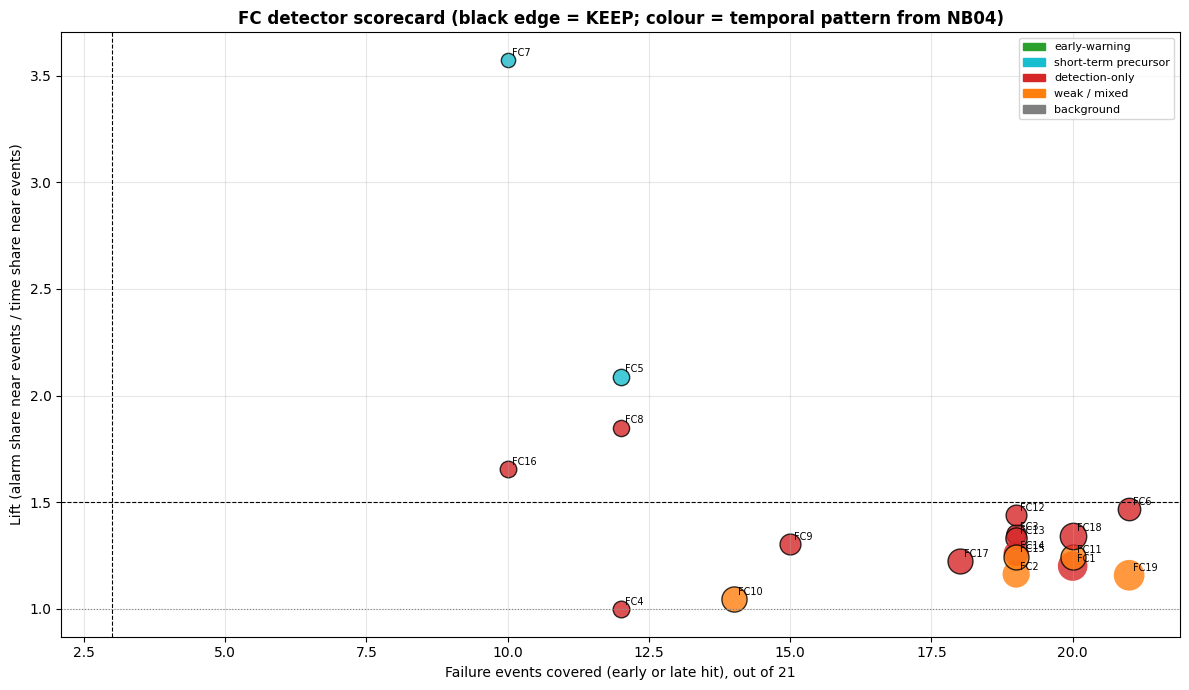

In [8]:
fig, ax = plt.subplots(figsize=(12, 7))
pat_col = {'early-warning': '#2ca02c', 'short-term precursor': '#17becf', 'detection-only': '#d62728',
           'weak / mixed': '#ff7f0e', 'background': '#7f7f7f'}
for r in fc_scores.itertuples():
    ax.scatter(r.events_covered, r.lift, s=40 + 4 * r.alarms ** 0.5 * 4, color=pat_col.get(r.pattern, 'grey'),
               edgecolor='black' if r.verdict == 'KEEP' else 'none', alpha=0.8)
    ax.annotate(r.FC, (r.events_covered, r.lift), fontsize=7, xytext=(3, 3), textcoords='offset points')
ax.axhline(1.5, color='black', ls='--', lw=0.8); ax.axhline(1.0, color='grey', ls=':', lw=0.8)
ax.axvline(3, color='black', ls='--', lw=0.8)
ax.set_xlabel(f'Failure events covered (early or late hit), out of {n_ev}')
ax.set_ylabel('Lift (alarm share near events / time share near events)')
ax.set_title('FC detector scorecard (black edge = KEEP; colour = temporal pattern from NB04)', fontweight='bold')
ax.legend(handles=[Patch(color=c, label=p) for p, c in pat_col.items()], fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(NB05_OUT, 'fc_scorecard.png'), dpi=150, bbox_inches='tight')
plt.show()

## 4. Zooming into Prior-Work Flagged Intervals: Which FCs Sit Behind Early Hits and False Alarms?

The proposal builds RQ1 on the anomaly windows flagged by the prior MetroAT models. Steiner et al. (RAMS 2026, p7): *"Flagged intervals from either model can be used to zoom into test data, inspect contributing sensors, and identify recurring patterns behind FPs and true early hits."*

- **RF:** test-period predictions from NB02b (threshold tuned on the dev holdout). Until NB02b's grid search is run (Phase 2), these are the predictions of the earlier fixed-parameter RF (test F1 = 0.120).
- **LSTM-AE:** reconstruction scores from NB02b. No threshold was stored, so an alarm is a score above the 99th percentile of the **validation split** (normal train sequences held out from AE training). The model is rebuilt from the saved weights, and a check confirms it reproduces the saved test scores.
- **Note:** as in Helm's code, NB02a labels windows *inside* a failure as positive (label = failure within [window_end, window_end + 6.2 h)). This affects the RF's training target, not the episode classification used here.

Alarms are merged into episodes and classified with the same rules as §3. For the windows inside each episode we measure how often each FC is active and compare early-hit episodes with false-alarm episodes (Fisher's exact test, Bonferroni-corrected).

In [9]:
rf = pd.read_csv(os.path.join(OUT, 'supervised', 'test_predictions_rf.csv'),
                 usecols=['window_end', 'predicted_failure_label', 'probability_of_failure'], parse_dates=['window_end'])
ae = pd.read_parquet(os.path.join(OUT, 'unsupervised', 'full_period_lstmae_scores.parquet'))
ae['window_end'] = pd.to_datetime(ae['window_end'])
ae_test = ae[ae.split == 'test']

# LSTM-AE threshold from the VALIDATION split (normal train sequences held out from AE training in NB02b),
# not from all train scores, which include the AE's own training sequences (in-sample, too low).
import torch
import torch.nn as nn


class LSTMAutoencoder(nn.Module):  # same architecture as NB02b
    def __init__(self, n_channels, hidden_dim):
        super().__init__()
        self.encoder = nn.LSTM(n_channels, hidden_dim, batch_first=True)
        self.decoder = nn.LSTM(hidden_dim, hidden_dim, batch_first=True)
        self.output_layer = nn.Linear(hidden_dim, n_channels)

    def forward(self, x):
        _, (h, c) = self.encoder(x)
        dec_in = h.squeeze(0).unsqueeze(1).repeat(1, x.size(1), 1)
        out, _ = self.decoder(dec_in, (h, c))
        return self.output_layer(out)


with open(os.path.join(OUT, 'unsupervised', 'metadata.json')) as f:
    ae_meta = json.load(f)
model_ae = LSTMAutoencoder(len(ae_meta['channels']), 64)
model_ae.load_state_dict(torch.load(os.path.join(OUT, 'unsupervised', 'lstm_ae_model.pt'), map_location='cpu'))
model_ae.eval()


def ae_scores(arr, bs=256):
    out = []
    with torch.no_grad():
        for i in range(0, len(arr), bs):
            x = torch.from_numpy(np.asarray(arr[i:i + bs], dtype=np.float32))
            out.append(((x - model_ae(x)) ** 2).mean(dim=(1, 2)).numpy())
    return np.concatenate(out)


test_seqs = np.load(os.path.join(OUT, 'unsupervised', 'test.npy'), mmap_mode='r')
saved_test = pd.read_csv(os.path.join(OUT, 'unsupervised', 'test_predictions_lstmae.csv'))['anomaly_score_lstmae'].values
check = np.abs(ae_scores(test_seqs[:200]) - saved_test[:200]).max()
print(f'Reproduction check: max |recomputed - saved| test score over 200 sequences = {check:.2e}')
assert check < 1e-3, 'Rebuilt LSTM-AE does not reproduce the saved scores'
val_scores = ae_scores(np.load(os.path.join(OUT, 'unsupervised', 'val.npy'), mmap_mode='r'))
ae_thr = float(np.quantile(val_scores, 0.99))
in_sample_thr = ae.loc[(ae.split == 'train') & (ae.fail == 0), 'score'].quantile(0.99)
print(f'LSTM-AE threshold: 99th pct of {len(val_scores)} validation scores = {ae_thr:.3f} '
      f'(the in-sample train 99th pct would be {in_sample_thr:.3f})')

model_alarms = {
    'RF': (rf.loc[rf.predicted_failure_label == 1, 'window_end'], pd.Timedelta(minutes=30), pd.Timedelta(seconds=WINDOW_S)),
    'LSTM-AE': (ae_test.loc[ae_test.score > ae_thr, 'window_end'], pd.Timedelta(minutes=60), pd.Timedelta(seconds=1402)),
}
test_events = fail_events[fail_events.split == 'test']
model_eps = {}
for name, (times, gap, _) in model_alarms.items():
    eps = score_episodes(make_episodes(times, gap))
    model_eps[name] = eps
    early = {e for l in eps['early_events'] for e in l} & set(test_events.index)
    late = ({e for l in eps['late_events'] for e in l} - early) & set(test_events.index)
    print(f'{name}: {len(times)} alarm windows -> {len(eps)} episodes | '
          f'early hits {len(early)}/{len(test_events)} test events, late hits {len(late)}, '
          f'false-alarm episodes {(eps.kind == "false_alarm").sum()}, post-failure {(eps.kind == "post_failure").sum()}')
print(f'(LSTM-AE threshold = 99th percentile of validation-split scores = {ae_thr:.3f})')
print('For reference, RAMS 2026 reports RF 11/11 and LSTM-AE 9/11 early hits with 14 false alarms each '
      '(different smoothing/thresholds, so counts are not directly comparable).')

Reproduction check: max |recomputed - saved| test score over 200 sequences = 3.86e-08


LSTM-AE threshold: 99th pct of 1962 validation scores = 1.123 (the in-sample train 99th pct would be 1.142)
RF: 879 alarm windows -> 240 episodes | early hits 11/11 test events, late hits 0, false-alarm episodes 109, post-failure 15


LSTM-AE: 420 alarm windows -> 337 episodes | early hits 10/11 test events, late hits 0, false-alarm episodes 209, post-failure 10
(LSTM-AE threshold = 99th percentile of validation-split scores = 1.123)
For reference, RAMS 2026 reports RF 11/11 and LSTM-AE 9/11 early hits with 14 false alarms each (different smoothing/thresholds, so counts are not directly comparable).



=== RF: 467 windows in early-hit episodes, 502 windows in false-alarm episodes ===
  FC  rate_in_early_hits_%  rate_in_false_alarms_%  odds_ratio  p_adj characterises
 FC1                19.914                  10.558       2.107  0.001    early hits
 FC2                39.400                  52.590       0.586  0.001  false alarms
 FC3                 5.996                   6.574       0.906  1.000              
 FC4                 3.212                   1.793       1.818  1.000              
 FC5                 3.426                   1.594       2.191  1.000              
 FC6                19.914                  43.825       0.319  0.000  false alarms
 FC7                 2.141                   1.594       1.351  1.000              
 FC8                 8.565                   7.371       1.177  1.000              
 FC9                 7.281                   5.378       1.381  1.000              
FC10                 4.925                   5.179       0.948  1.000       


=== LSTM-AE: 675 windows in early-hit episodes, 1059 windows in false-alarm episodes ===
  FC  rate_in_early_hits_%  rate_in_false_alarms_%  odds_ratio  p_adj characterises
 FC1                 4.148                   0.755       5.685  0.000    early hits
 FC2                12.000                   5.099       2.538  0.000    early hits
 FC3                 4.593                   3.872       1.195  1.000              
 FC4                 2.519                   2.172       1.164  1.000              
 FC5                 2.667                   1.322       2.045  0.871              
 FC6                 4.741                   3.966       1.205  1.000              
 FC7                 0.000                   0.094       0.000  1.000              
 FC8                 0.889                   1.039       0.854  1.000              
 FC9                 5.926                   2.266       2.717  0.002    early hits
FC10                23.556                   6.893       4.162  0.000 

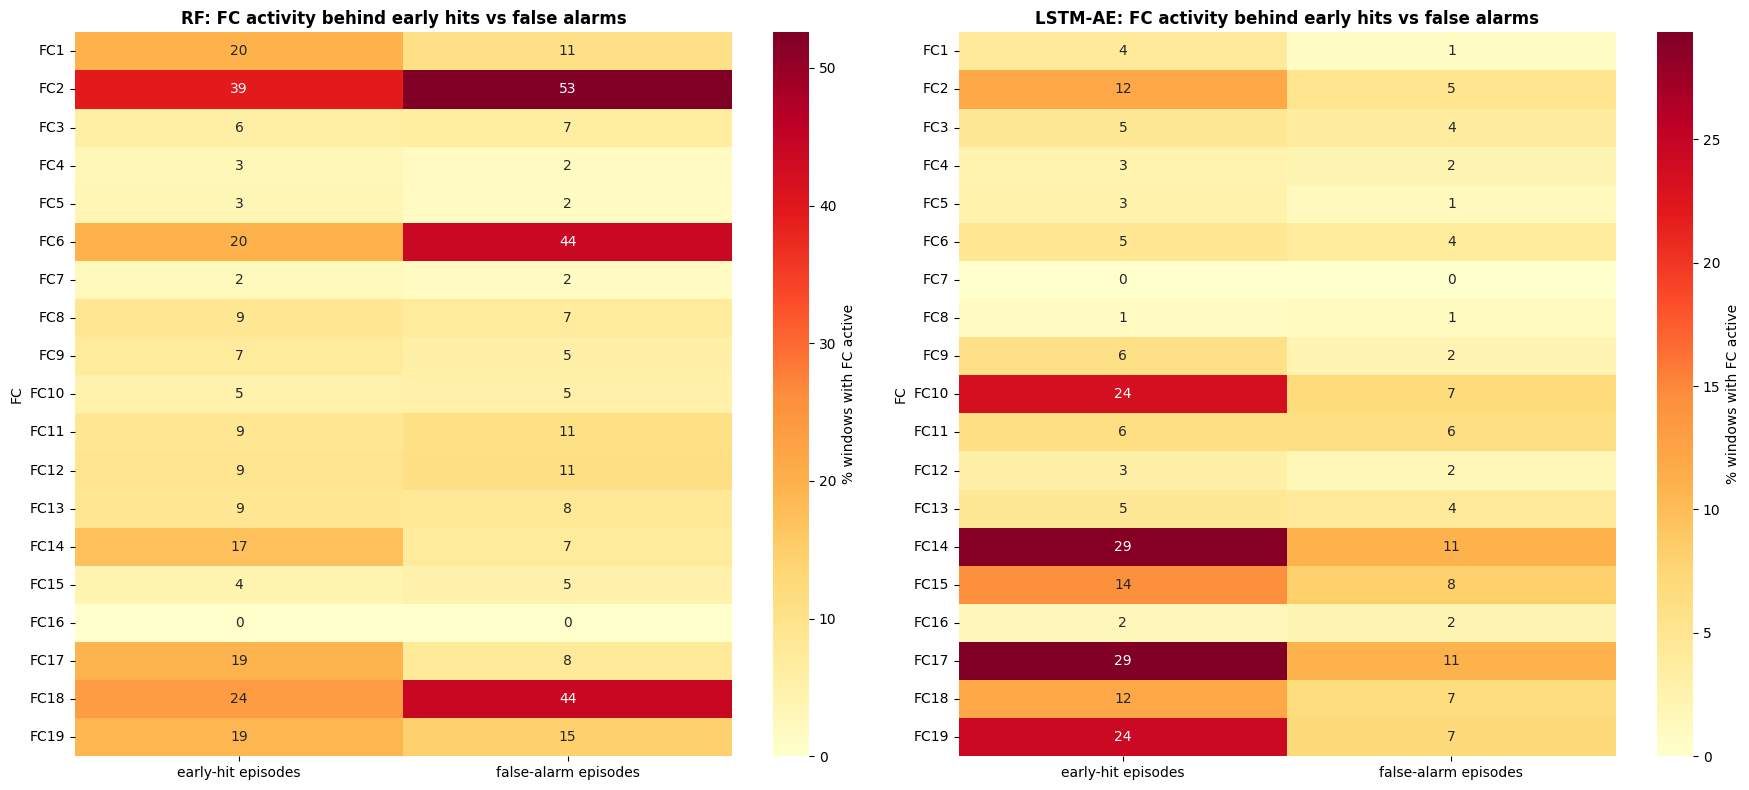

In [10]:
win_times = all_sup['window_end']
enrich_tables = {}
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, (name, (_, _, span)) in zip(axes, model_alarms.items()):
    eps = model_eps[name]
    idx = {'early_hit': [], 'false_alarm': []}
    for r in eps.itertuples():
        if r.kind in idx:
            m = (win_times >= r.start - span) & (win_times <= r.end)
            idx[r.kind].extend(all_sup.index[m])
    eh, fa = pd.Index(sorted(set(idx['early_hit']))), pd.Index(sorted(set(idx['false_alarm'])))
    rows = []
    for fc in fc_ids:
        a, b = int(fc_act_all.loc[eh, fc].sum()), len(eh) - int(fc_act_all.loc[eh, fc].sum())
        c, d = int(fc_act_all.loc[fa, fc].sum()), len(fa) - int(fc_act_all.loc[fa, fc].sum())
        odds, p = fisher_exact([[a, b], [c, d]]) if len(eh) and len(fa) else (np.nan, 1.0)
        p_adj = min(1.0, p * len(fc_ids))
        tag = ('early hits' if odds > 1 else 'false alarms') if p_adj < 0.05 else ''
        rows.append({'FC': f'FC{fc}', 'rate_in_early_hits_%': 100 * a / max(len(eh), 1),
                     'rate_in_false_alarms_%': 100 * c / max(len(fa), 1), 'odds_ratio': odds, 'p_adj': p_adj,
                     'characterises': tag})
    t = pd.DataFrame(rows)
    enrich_tables[name] = t
    print(f'\n=== {name}: {len(eh)} windows in early-hit episodes, {len(fa)} windows in false-alarm episodes ===')
    print(t.round(3).to_string(index=False))
    sig = t[t.characterises != '']
    print(f'Significant: {", ".join(sig.FC + " -> " + sig.characterises) or "none"}')
    hm = t.set_index('FC')[['rate_in_early_hits_%', 'rate_in_false_alarms_%']]
    sns.heatmap(hm, ax=ax, cmap='YlOrRd', annot=True, fmt='.0f', cbar_kws={'label': '% windows with FC active'})
    ax.set_xticklabels(['early-hit episodes', 'false-alarm episodes'])
    ax.set_title(f'{name}: FC activity behind early hits vs false alarms', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(NB05_OUT, 'prior_model_fc_enrichment.png'), dpi=150, bbox_inches='tight')
plt.show()

## 5. FCs vs Failure Types Recorded by Wiener Linien

Each failure event carries the type Wiener Linien recorded (Brake System / Compressor Module / Leveling System). For each type, the table shows how much more often an FC fires in the **last 24 h before onset and during the failure** than in normal periods of the same period (train/test). A value of 1 means no difference; higher values mean the FC is more active around failures of that type. A wider window (e.g. 6 days) is uninformative, because almost every FC fires at least once in 6 days.

These are **Wiener Linien's labels for failures, not our labels for clusters**. The table is evidence for the experts. No FC is assigned to a subsystem here.

Enrichment in the last 24 h + during failure, vs same-period normal rate:
      Brake System Failure (n=13)  Compressor Module Failure (n=6)  Leveling System Failure (n=2)
FC1                           1.6                              1.9                            3.1
FC2                           3.2                              2.9                            5.2
FC3                           3.2                              0.6                            1.4
FC4                           2.6                              1.3                            1.0
FC5                           4.2                              4.0                           10.5
FC6                           6.5                              3.4                            2.1
FC7                          62.2                              3.4                           23.1
FC8                          11.6                              4.5                            5.2
FC9                           3.8           

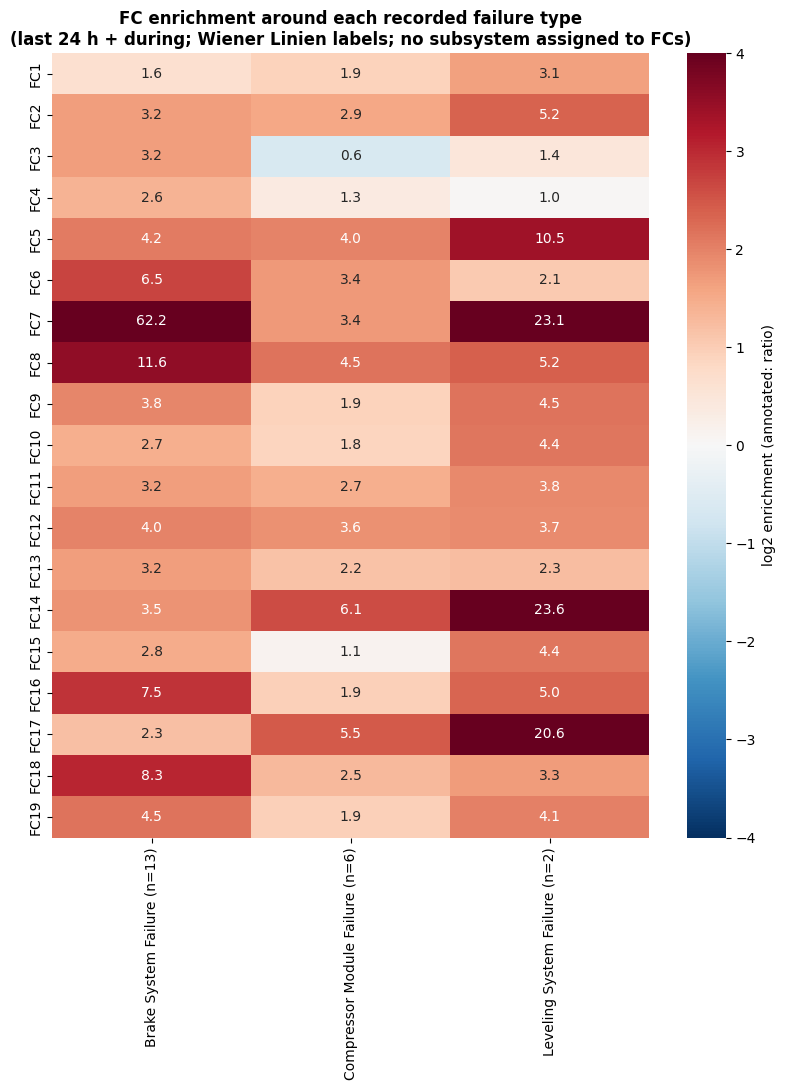

In [11]:
phase = all_sup['phase'].values
ev_id = all_sup['ev_id'].values
split_arr = all_sup['split'].values
near_fail = np.isin(phase, ['imminent', 'during'])
types = fail_events['event_type'].value_counts().index.tolist()
type_tab = pd.DataFrame(index=[f'FC{fc}' for fc in fc_ids], columns=types, dtype=float)
type_events = pd.DataFrame(index=type_tab.index, columns=types, dtype=object)
for t in types:
    evs = fail_events.index[fail_events.event_type == t]
    m_t = near_fail & np.isin(ev_id, evs)
    for fc in fc_ids:
        act = fc_act_all[fc].values
        base = {sp: act[(phase == 'normal') & (split_arr == sp)].mean() for sp in ('train', 'test')}
        expected = sum((m_t & (split_arr == sp)).sum() * base[sp] for sp in base)
        type_tab.loc[f'FC{fc}', t] = act[m_t].sum() / expected if expected > 0 else np.nan
        type_events.loc[f'FC{fc}', t] = f'{sum((act & m_t & (ev_id == e)).any() for e in evs)}/{len(evs)}'
type_tab.columns = type_events.columns = [f'{t} (n={int((fail_events.event_type == t).sum())})' for t in types]
print('Enrichment in the last 24 h + during failure, vs same-period normal rate:')
print(type_tab.round(1).to_string())
print('\nEvents of each type in which the FC fires in that window:')
print(type_events.to_string())

fig, ax = plt.subplots(figsize=(8, 11))
sns.heatmap(np.log2(type_tab.astype(float).clip(lower=1/32, upper=32)), ax=ax, cmap='RdBu_r', center=0, vmin=-4, vmax=4,
            annot=type_tab.round(1), fmt='', cbar_kws={'label': 'log2 enrichment (annotated: ratio)'})
ax.set_title('FC enrichment around each recorded failure type\n(last 24 h + during; Wiener Linien labels; no subsystem assigned to FCs)',
             fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(NB05_OUT, 'fc_failure_type.png'), dpi=150, bbox_inches='tight')
plt.show()

## 6. Timeline: FC Activations vs Failure Events

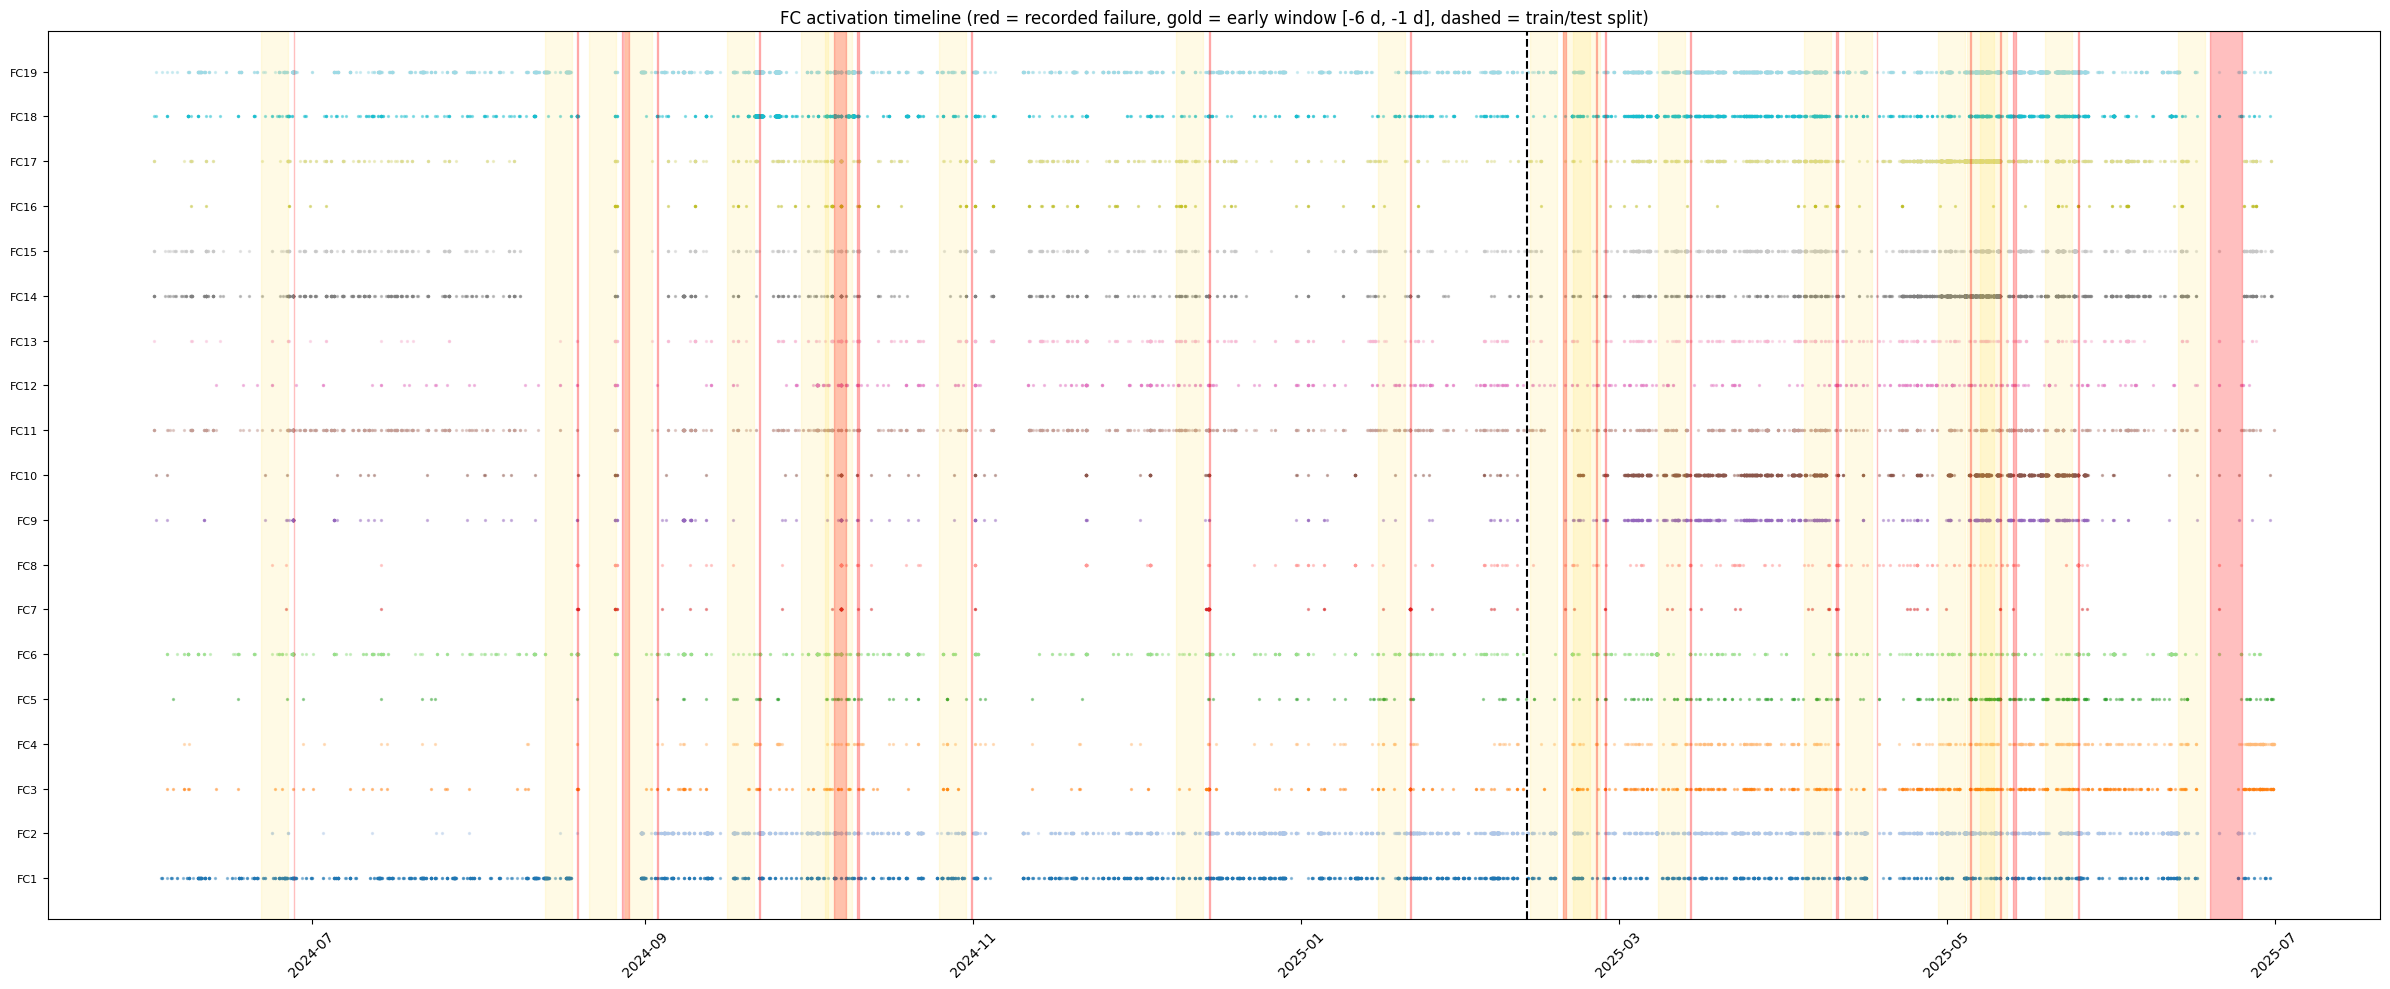

In [12]:
fig, ax = plt.subplots(figsize=(24, 10))
cmap = plt.cm.tab20(np.linspace(0, 1, len(fc_ids)))
for row, fc in enumerate(fc_ids):
    t = all_sup.loc[fc_act_all[fc], 'window_end']
    ax.scatter(t, np.full(len(t), row), s=2, alpha=0.4, color=cmap[row])
for ev in fail_events.itertuples():
    ax.axvspan(ev.start - pd.Timedelta(days=6), ev.start - pd.Timedelta(days=1), color='gold', alpha=0.10)
    ax.axvspan(ev.start, ev.end + pd.Timedelta(hours=1), color='red', alpha=0.25)
ax.axvline(SPLIT_DATE, color='black', ls='--', lw=1.5)
ax.set_yticks(range(len(fc_ids))); ax.set_yticklabels([f'FC{fc}' for fc in fc_ids], fontsize=8)
ax.set_title('FC activation timeline (red = recorded failure, gold = early window [-6 d, -1 d], dashed = train/test split)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(NB05_OUT, 'fc_timeline.png'), dpi=150, bbox_inches='tight')
plt.show()

## 7. Deep Dives

FCs are selected from the results rather than fixed in advance: the strongest KEEP FC by train lift, plus the strongest early-warning, short-term precursor and detection-only FC from NB04 §4.3 (where such FCs exist). Plots show the daily mean ± std of each top feature, with recorded failures in red. Sensor names are shown as they are; interpretation is left to the experts.

Deep-dive FCs: FC7, FC8

FC7: 2 features | alarms 17, early hits 4, late hits 6, false alarms 1, lift 3.57, median lead 0.7 h
  CW1_SPRING_BRAKE_PRESSURE_BOGIE2_min: active in 99.3% of the FC windows
  CW1_LOAD_PRESSURE_BOGIE2_max: active in 48.5% of the FC windows


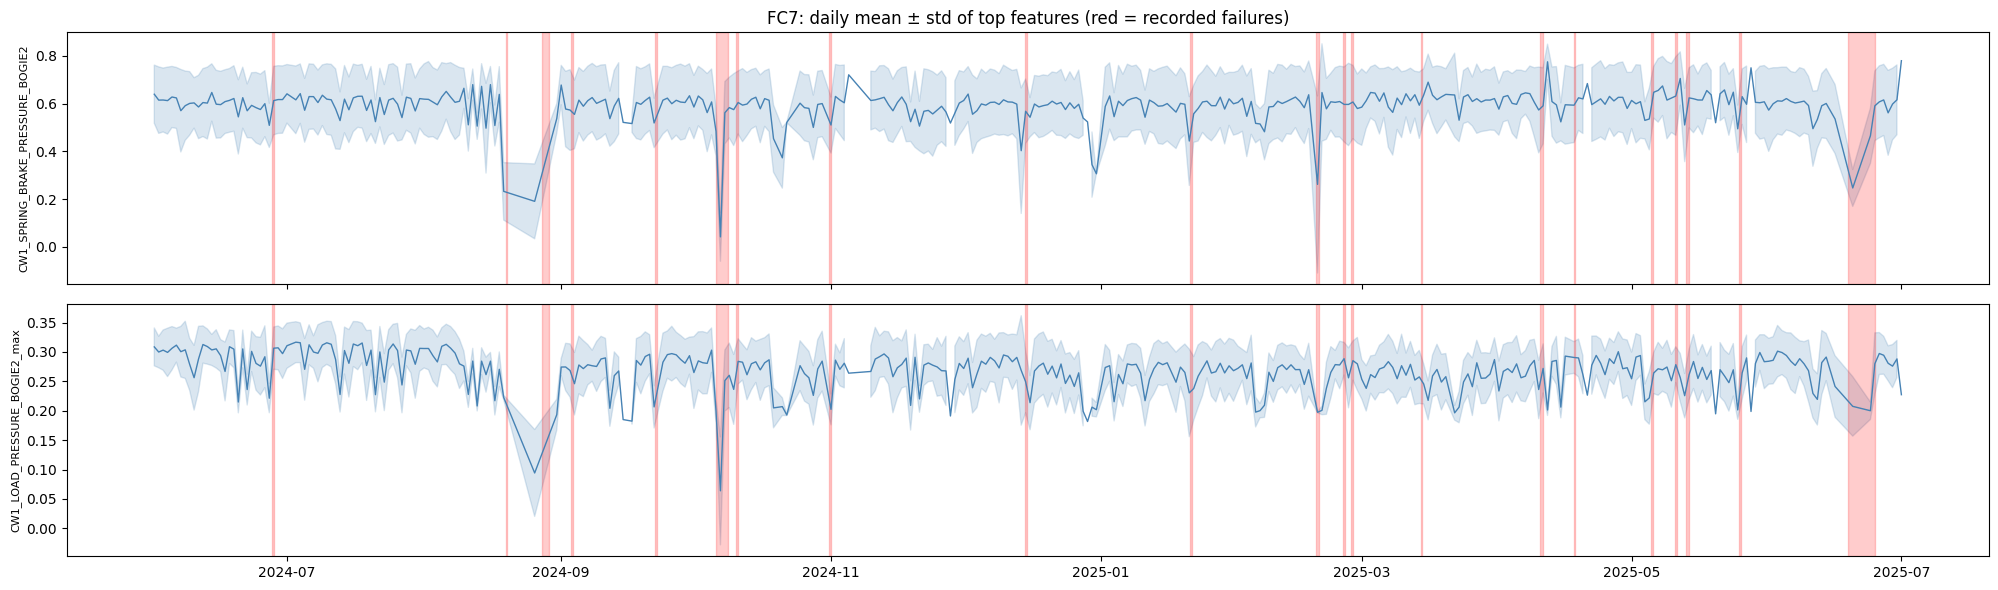


FC8: 7 features | alarms 36, early hits 6, late hits 6, false alarms 14, lift 1.85, median lead 4.5 h
  MW4_SPRING_BRAKE_PRESSURE_BOGIE1_min: active in 73.4% of the FC windows
  MW4_SPRING_BRAKE_PRESSURE_BOGIE2_min: active in 70.5% of the FC windows
  MW2_SPRING_BRAKE_PRESSURE_BOGIE1_min: active in 60.1% of the FC windows
  MW3_SPRING_BRAKE_PRESSURE_BOGIE1_min: active in 55.0% of the FC windows
  MW2_SPRING_BRAKE_PRESSURE_BOGIE2_min: active in 53.5% of the FC windows


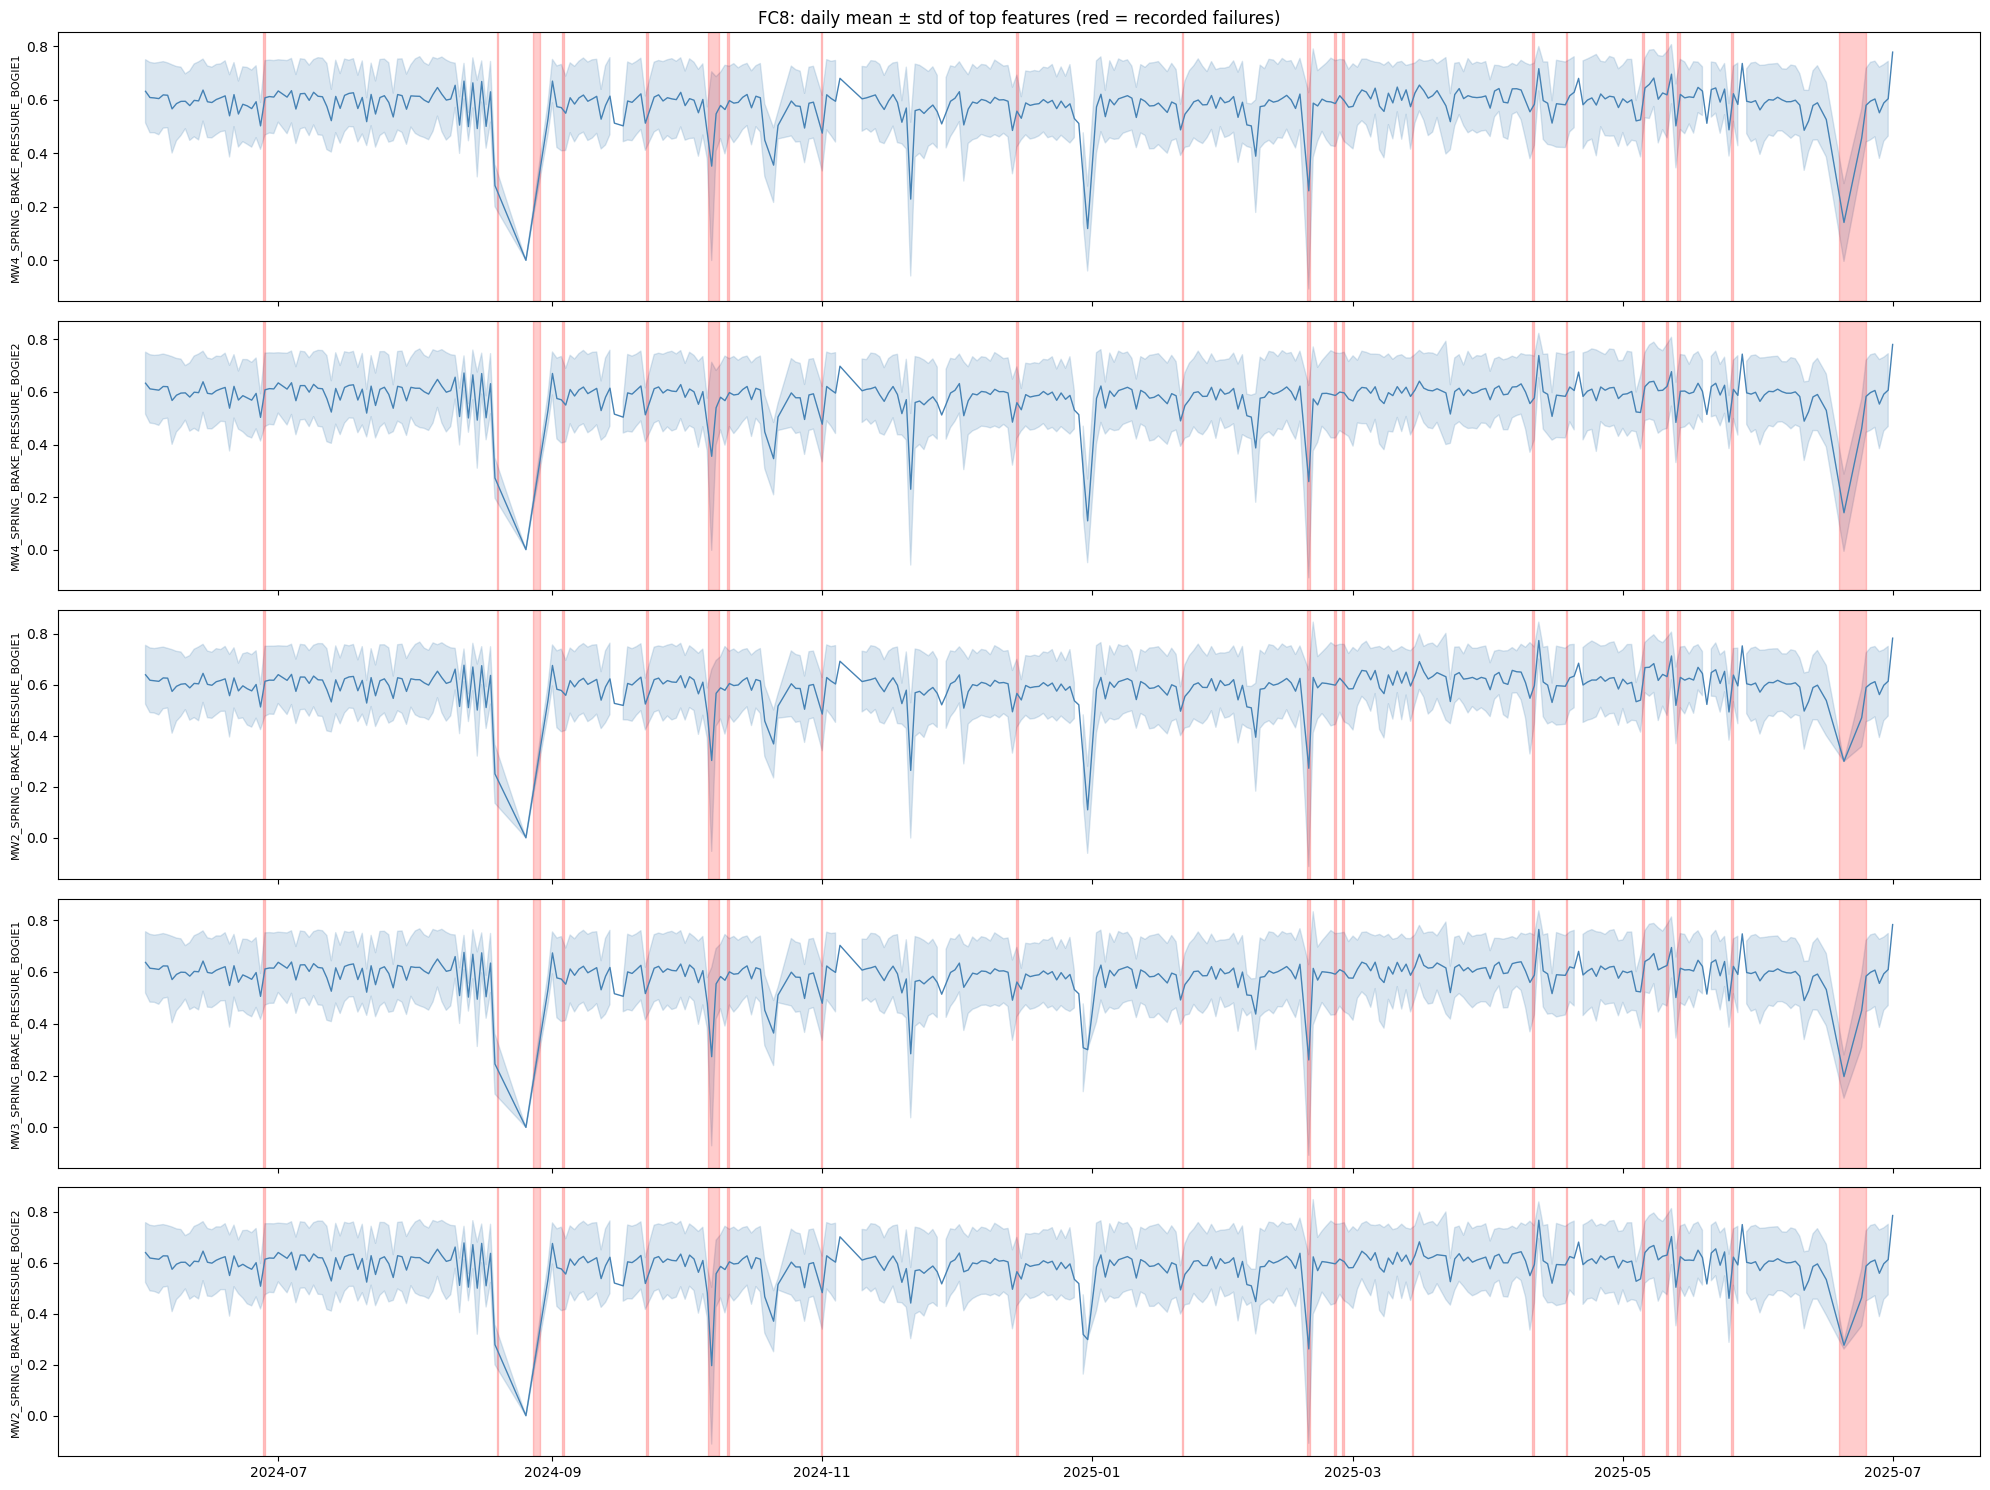

In [13]:
picks = []
keep = fc_scores[fc_scores.verdict == 'KEEP'].sort_values('lift_train', ascending=False)
if len(keep): picks.append(int(keep.iloc[0].fc_id))
for pat, col in (('early-warning', 'enrich_early'), ('short-term precursor', 'enrich_imminent'), ('detection-only', 'enrich_during')):
    cand = fc_temporal[fc_temporal.pattern == pat].sort_values(col, ascending=False)
    if len(cand): picks.append(int(cand.iloc[0].fc_id))
picks = list(dict.fromkeys(picks))
print('Deep-dive FCs:', ', '.join(f'FC{p}' for p in picks))


def deep_dive_fc(fc, n_top=5):
    feats = clusters[fc]
    act = anom_activations[feats].any(axis=1)
    top = anom_activations.loc[act, feats].mean().sort_values(ascending=False).head(min(n_top, len(feats)))
    s = fc_scores.set_index('FC').loc[f'FC{fc}']
    print(f'\n{"=" * 80}\nFC{fc}: {len(feats)} features | alarms {s.alarms}, early hits {s.early_hits}, late hits {s.late_hits}, '
          f'false alarms {s.false_alarms}, lift {s.lift:.2f}, median lead {s.median_lead_h:.1f} h')
    for f, r in top.items():
        print(f'  {f}: active in {r:.1%} of the FC windows')
    fig, axes = plt.subplots(len(top), 1, figsize=(20, 3 * len(top)), sharex=True, squeeze=False)
    for ax, f in zip(axes[:, 0], top.index):
        daily = all_sup.groupby(all_sup['window_end'].dt.date)[f].agg(['mean', 'std'])
        daily.index = pd.to_datetime(daily.index)
        ax.plot(daily.index, daily['mean'], color='steelblue', lw=1)
        ax.fill_between(daily.index, daily['mean'] - daily['std'], daily['mean'] + daily['std'], alpha=0.2, color='steelblue')
        for ev in fail_events.itertuples():
            ax.axvspan(ev.start, ev.end + pd.Timedelta(hours=6), color='red', alpha=0.2)
        ax.set_ylabel(f[:32], fontsize=8)
    axes[0, 0].set_title(f'FC{fc}: daily mean ± std of top features (red = recorded failures)')
    plt.tight_layout()
    plt.savefig(os.path.join(NB05_OUT, f'fc{fc}_deep_dive.png'), dpi=150, bbox_inches='tight')
    plt.show()


for fc in picks:
    deep_dive_fc(fc)

### 7.1 Top-10 Features per FC with Values (supervisor feedback: "top-10 features with numerical statistics")

For every FC, its 10 most frequently activated features, ranked by how often each is activated when the FC fires. For each feature:
- **normal range:** median and 5th–95th percentile in normal training windows (the same reference as the z-scores in NB04),
- **when FC active:** median value in the windows where the FC fires,
- **shift:** that median expressed in normal standard deviations (positive = higher than normal, negative = lower).

Values are in the units of the public MetroAT dataset (scaled signals), so the shift column is the easiest to compare across sensors. Saved as `fc_top10_features.csv`.

In [14]:
normal_ref = all_sup[(all_sup['split'] == 'train') & (all_sup['label'] == 0)]
rows = []
for fc in fc_ids:
    feats = clusters[fc]
    act = anom_activations[feats].any(axis=1)
    act_idx = anom_activations.index[act]
    share = anom_activations.loc[act, feats].mean().sort_values(ascending=False).head(10)
    for rank, (f, r) in enumerate(share.items(), start=1):
        ref = normal_ref[f]
        mu, sd = ref.mean(), ref.std()
        val = all_sup.loc[act_idx, f].median()
        rows.append({'FC': f'FC{fc}', 'rank': rank, 'feature': f, 'active_share': r,
                     'normal_median': ref.median(), 'normal_p05': ref.quantile(0.05), 'normal_p95': ref.quantile(0.95),
                     'fc_active_median': val, 'shift_in_std': (val - mu) / sd if sd > 0 else np.nan})
fc_top10 = pd.DataFrame(rows)
fc_top10.to_csv(os.path.join(NB05_OUT, 'fc_top10_features.csv'), index=False)

robust_fcs = fc_scores.loc[fc_scores.test_check == 'holds', 'FC'].tolist()
show = fc_top10[fc_top10.FC.isin(robust_fcs)].copy()
show['normal range (p05-p95)'] = show.apply(lambda r: f"{r.normal_p05:.3g} - {r.normal_p95:.3g}", axis=1)
print(f'FCs that hold on the test period: {", ".join(robust_fcs)} (all 19 FCs in fc_top10_features.csv)\n')
print(show[['FC', 'rank', 'feature', 'active_share', 'normal_median', 'normal range (p05-p95)', 'fc_active_median', 'shift_in_std']]
      .round({'active_share': 2, 'normal_median': 3, 'fc_active_median': 3, 'shift_in_std': 1}).to_string(index=False))

FCs that hold on the test period: FC5, FC7, FC8 (all 19 FCs in fc_top10_features.csv)

 FC  rank                              feature  active_share  normal_median normal range (p05-p95)  fc_active_median  shift_in_std
FC5     1         CW2_COMPRESSOR_RUNNING_flips          1.00          0.000                  0 - 1             4.000           5.6
FC7     1 CW1_SPRING_BRAKE_PRESSURE_BOGIE2_min          0.99          0.658           0.294 - 0.74             0.000          -4.3
FC7     2         CW1_LOAD_PRESSURE_BOGIE2_max          0.49          0.285          0.189 - 0.348             0.203          -1.5
FC8     1 MW4_SPRING_BRAKE_PRESSURE_BOGIE1_min          0.73          0.645          0.299 - 0.734             0.005          -4.3
FC8     2 MW4_SPRING_BRAKE_PRESSURE_BOGIE2_min          0.70          0.646          0.291 - 0.735             0.007          -4.3
FC8     3 MW2_SPRING_BRAKE_PRESSURE_BOGIE1_min          0.60          0.652           0.302 - 0.74             0.105          -

### 7.2 Raw 1-Second Signals Behind the Robust FCs (supervisor feedback: "back-calculations", "underlying values")

The windows in NB04 are 6-minute summaries. Here the original 1-second signals are read back from the raw MetroAT files for the FCs that hold on the test period. For each FC, the failure with the most FC activity in the 24 h before onset is shown from 24 h before onset to the end of the failure (at most 12 h after onset):
- **analog sensors:** the raw 1 Hz values,
- **on/off signals:** the number of switches per 10 minutes (counted from the 1 Hz signal), because the raw on/off trace is too dense to read,
- **markers:** the 6-minute windows in which the FC fires; **red:** the recorded failure.

FC5: event 18 (Leveling System Failure, onset 2025-05-10 20:25) | 67,570 raw rows | FC fires in 18 windows of this period | sensors: CW2_COMPRESSOR_RUNNING


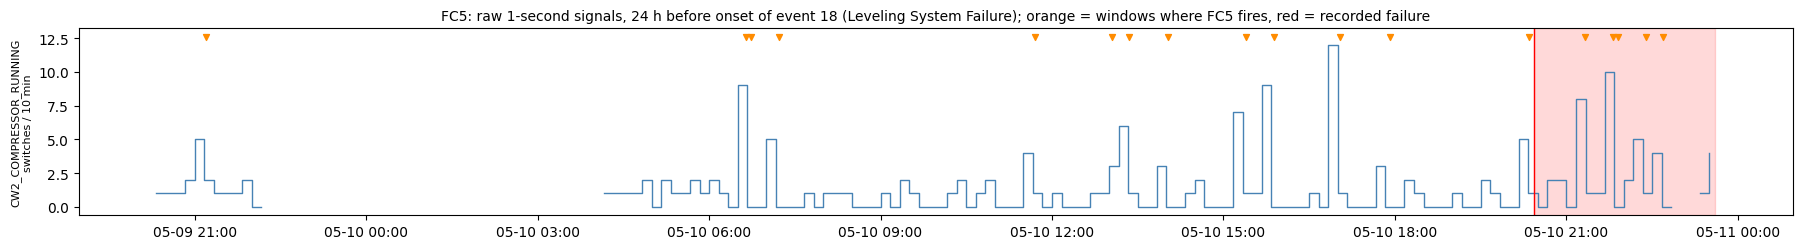

FC7: event 9 (Brake System Failure, onset 2024-12-14 18:56) | 53,175 raw rows | FC fires in 30 windows of this period | sensors: CW1_SPRING_BRAKE_PRESSURE_BOGIE2, CW1_LOAD_PRESSURE_BOGIE2


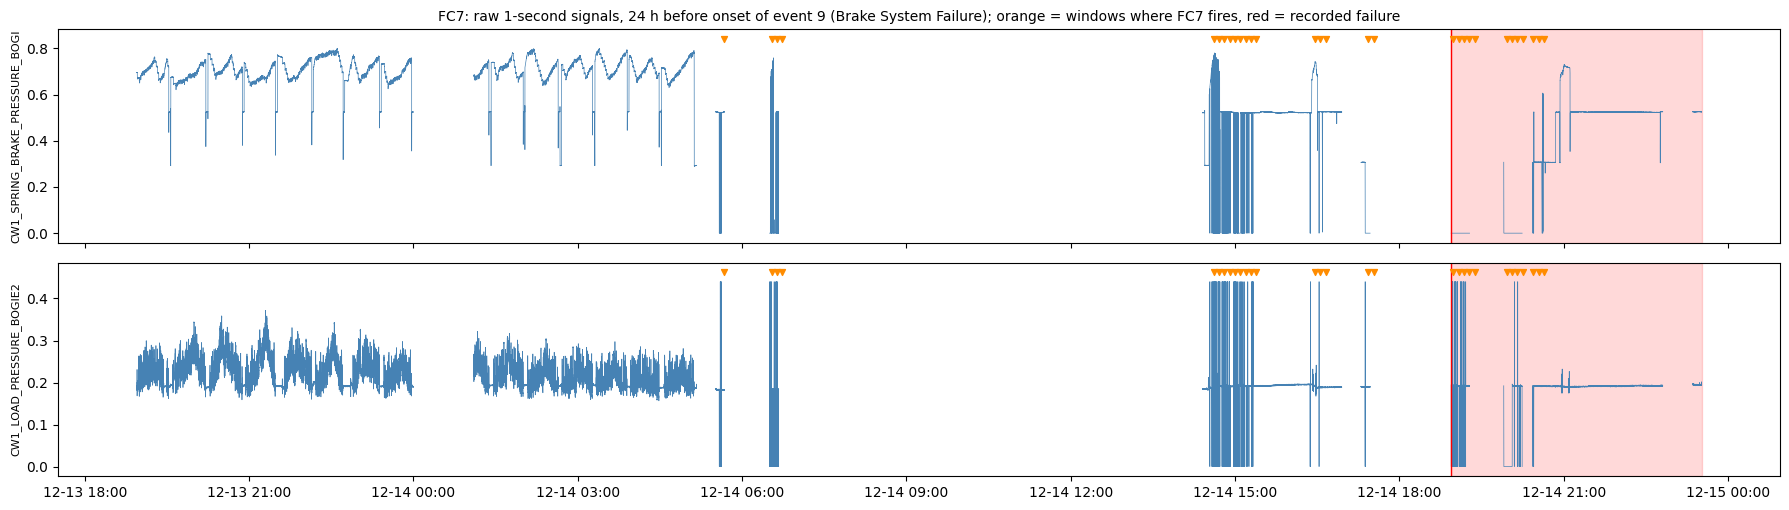

FC8: event 2 (Brake System Failure, onset 2024-08-19 10:37) | 35,289 raw rows | FC fires in 9 windows of this period | sensors: MW4_SPRING_BRAKE_PRESSURE_BOGIE1, MW4_SPRING_BRAKE_PRESSURE_BOGIE2, MW2_SPRING_BRAKE_PRESSURE_BOGIE1, MW3_SPRING_BRAKE_PRESSURE_BOGIE1


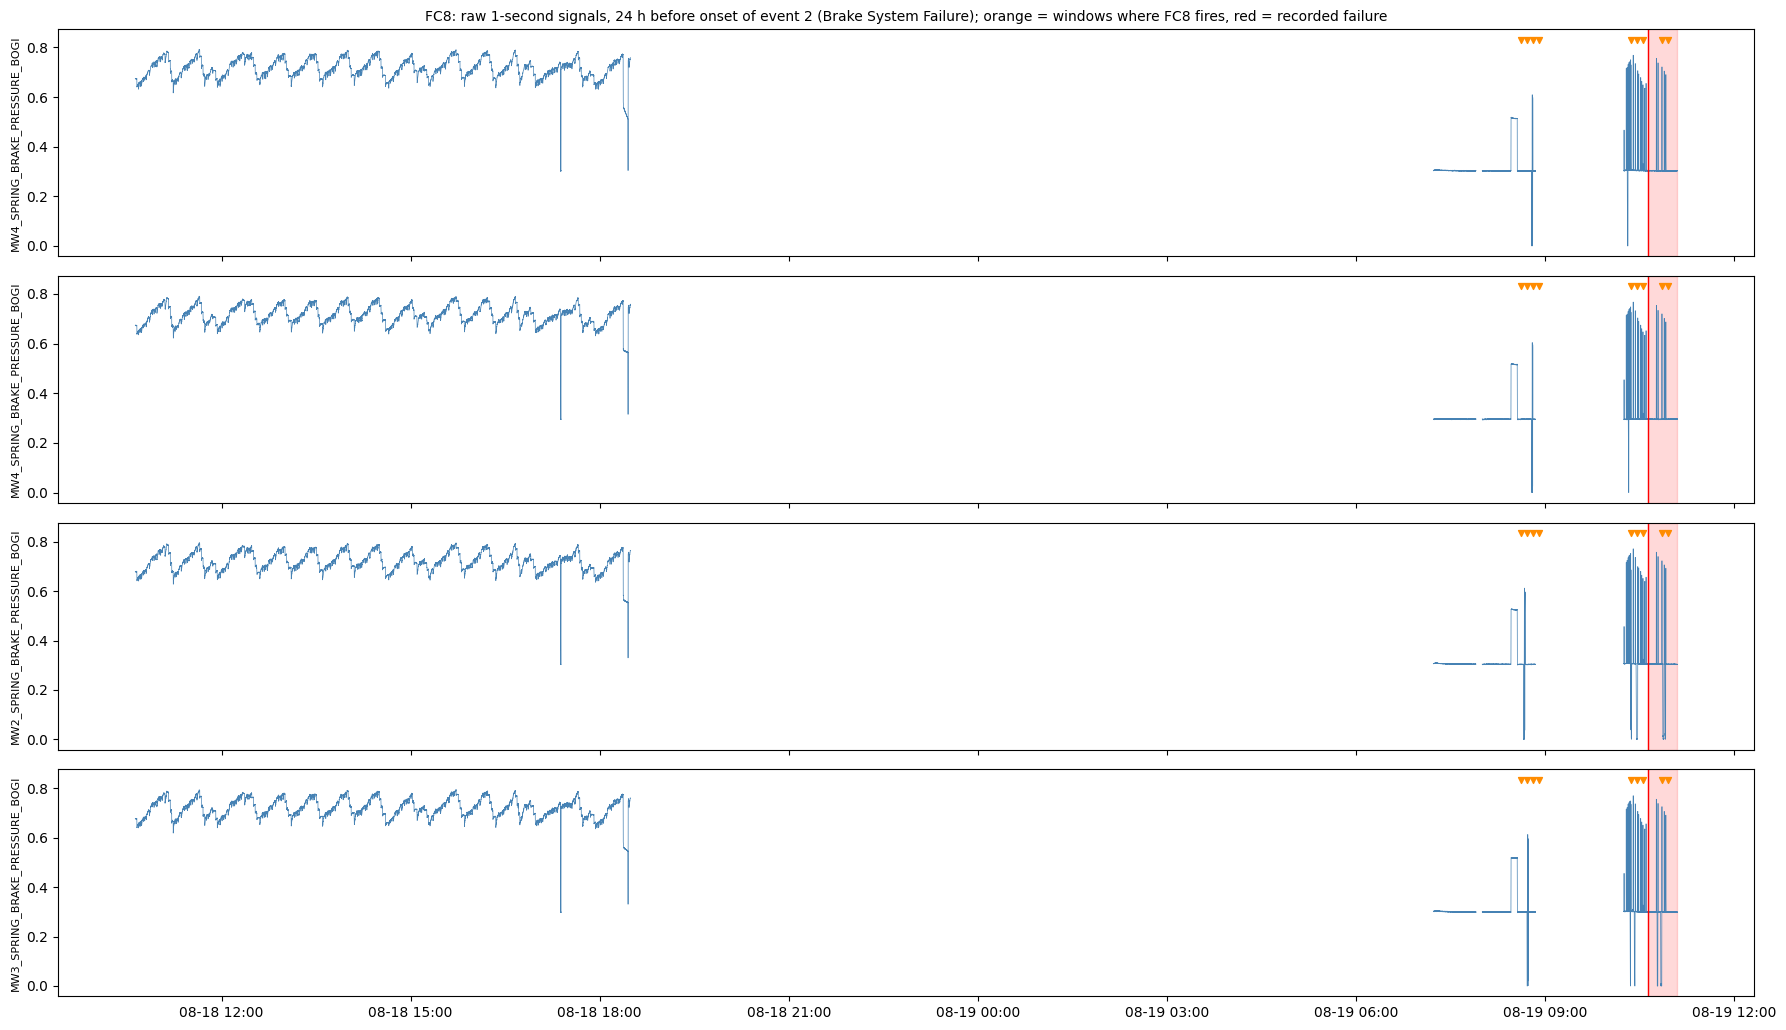

In [15]:
import glob as _glob


def base_sensor(feature):
    for suf in ('_active_s', '_flips', '_min', '_max', '_mean', '_sum'):
        if feature.endswith(suf):
            return feature[:-len(suf)]
    return feature


def read_raw(start, end, cols):
    # Raw rows between start and end from the train/ and test/ day files (only the needed columns)
    frames = []
    for day in pd.date_range(start.normalize(), end.normalize(), freq='D'):
        for split in ('train', 'test'):
            for f in _glob.glob(os.path.join(ROOT, split, f'year={day.year}', f'month={day.month:02d}', f'day={day.day:02d}', '*.parquet')):
                df = pd.read_parquet(f, columns=['TIMESTAMP'] + cols)
                df['TIMESTAMP'] = pd.to_datetime(df['TIMESTAMP'])
                frames.append(df[(df.TIMESTAMP >= start) & (df.TIMESTAMP <= end)])
    return pd.concat(frames).sort_values('TIMESTAMP') if frames else pd.DataFrame(columns=['TIMESTAMP'] + cols)


for fc_name in robust_fcs:
    fc = int(fc_name[2:])
    top = fc_top10[fc_top10.FC == fc_name].feature.tolist()
    sensors = list(dict.fromkeys(base_sensor(f) for f in top))[:4]
    near = all_sup.index[fc_act_all[fc] & (all_sup['phase'] == 'imminent')]
    counts = all_sup.loc[near, 'ev_id'].value_counts()
    ev = int(counts.index[0]) if len(counts) else int(all_sup.loc[fc_act_all[fc], 'ev_id'].dropna().mode().iloc[0])
    e = fail_events.loc[ev]
    t0, t1 = e.start - pd.Timedelta(hours=24), min(e.end, e.start + pd.Timedelta(hours=12))
    raw = read_raw(t0, t1, sensors)
    fires = all_sup.loc[fc_act_all[fc] & all_sup.window_end.between(t0, t1), 'window_end']
    print(f'{fc_name}: event {ev} ({e.event_type}, onset {e.start:%Y-%m-%d %H:%M}) | {len(raw):,} raw rows | '
          f'FC fires in {len(fires)} windows of this period | sensors: {", ".join(sensors)}')

    fig, axes = plt.subplots(len(sensors), 1, figsize=(18, 2.6 * len(sensors)), sharex=True, squeeze=False)
    for ax, s in zip(axes[:, 0], sensors):
        sig = raw.set_index('TIMESTAMP')[s].astype(float)
        if sig.dropna().isin([0, 1]).all():
            switches = sig.diff().abs().resample('10min').sum(min_count=1)
            ax.step(switches.index, switches.values, where='post', color='steelblue', lw=1)
            ax.set_ylabel(f'{s[:28]}\nswitches / 10 min', fontsize=8)
        else:
            gap = sig.index.to_series().diff() > pd.Timedelta(minutes=5)  # no line across times without data
            ax.plot(sig.index, sig.where(~gap.values).values, color='steelblue', lw=0.5)
            ax.set_ylabel(s[:30], fontsize=8)
        ax.axvspan(e.start, e.end, color='red', alpha=0.15)
        ax.axvline(e.start, color='red', lw=1)
        ymax = ax.get_ylim()[1]
        ax.scatter(fires, np.full(len(fires), ymax), marker='v', color='darkorange', s=18, zorder=3, clip_on=False)
    axes[0, 0].set_title(f'{fc_name}: raw 1-second signals, 24 h before onset of event {ev} ({e.event_type}); '
                         f'orange = windows where {fc_name} fires, red = recorded failure', fontsize=10)
    axes[-1, 0].xaxis.set_major_formatter(mdates.DateFormatter('%m-%d %H:%M'))
    plt.tight_layout()
    plt.savefig(os.path.join(NB05_OUT, f'{fc_name.lower()}_raw_signals.png'), dpi=150, bbox_inches='tight')
    plt.show()

### 7.3 Random Forest Feature Importance Grouped by FC (meeting goal: "feature importance: feature → event → failure")

Which inputs does the full-feature Random Forest baseline rely on, and do they belong to the FCs? The RF's impurity-based feature importances (sum to 1) are added up per FC. Features outside the FCs are split into: context and asset features (speed, temperature, days since the last failure or revision), `_sum` features (dropped in NB04 as near-copies of `_mean`) and other sensor features that are not in any FC.

Uses the RF currently in `outputs/supervised/rf_model.joblib` (raw, untuned version); re-run after NB02b in Phase 2. Impurity importance favours features with many distinct values and is spread across correlated features, so it shows where the model looks, not causal relevance. Saved as `rf_importance_by_fc.csv`.

Top 15 RF features:
                                         importance                   group
MW3_SPRING_BRAKE_PRESSURE_BOGIE2_mean        0.0415                    FC18
MW4_LOAD_PRESSURE_BOGIE1_max                 0.0346   sensor feature, no FC
MW3_SPRING_BRAKE_PRESSURE_BOGIE2_sum         0.0333  _sum (dropped in NB04)
MW4_LOAD_PRESSURE_BOGIE1_mean                0.0332                    FC14
MW3_SPRING_BRAKE_PRESSURE_BOGIE2_max         0.0230                    FC18
MW3_SPRING_BRAKE_PRESSURE_BOGIE2_min         0.0223                    FC18
MW3_BRAKE_CYLINDER_PRESSURE_BOGIE2_min       0.0214                     FC1
MW1_SPRING_BRAKE_PRESSURE_BOGIE2_mean        0.0203                     FC6
MW3_BRAKE_CYLINDER_PRESSURE_BOGIE2_mean      0.0179   sensor feature, no FC
MW3_LOAD_PRESSURE_BOGIE2_min                 0.0177                    FC18
CW1_SPRING_BRAKE_PRESSURE_BOGIE2_min         0.0175                     FC7
MW3_LOAD_PRESSURE_BOGIE2_max                 0.0174                 

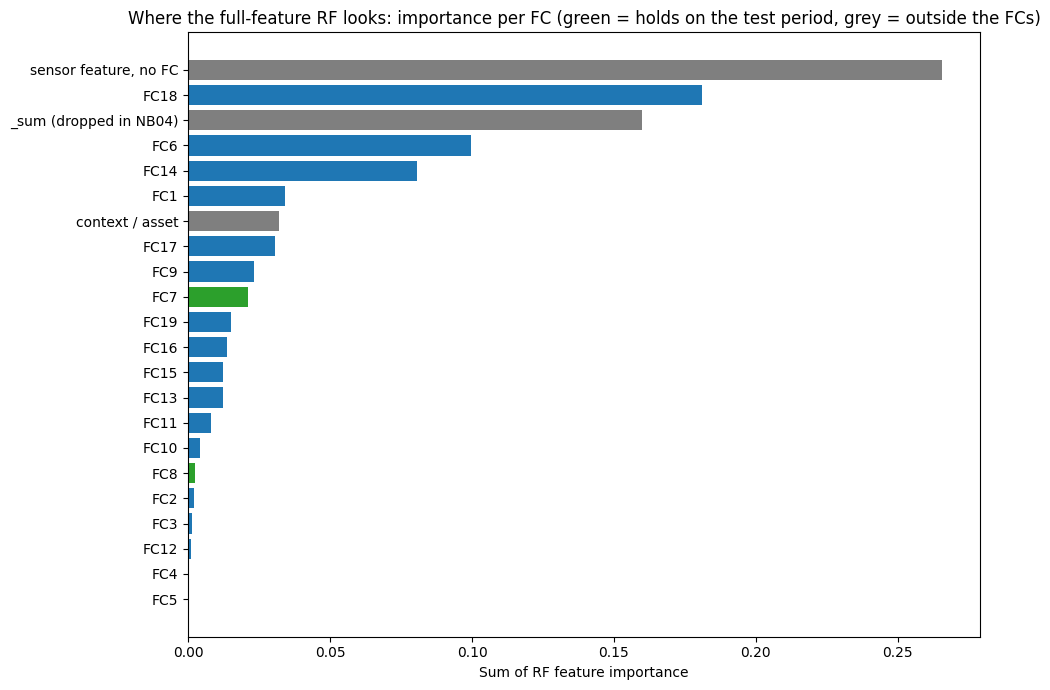

In [16]:
import joblib

rf_saved = joblib.load(os.path.join(OUT, 'supervised', 'rf_model.joblib'))
rf_pipe = rf_saved['model']
imp = pd.Series(rf_pipe.named_steps['clf'].feature_importances_,
                index=rf_pipe.named_steps['pre'].get_feature_names_out()).sort_values(ascending=False)

feat_to_fc = {f: f'FC{fc}' for fc in fc_ids for f in clusters[fc]}


def importance_group(f):
    if f in feat_to_fc:
        return feat_to_fc[f]
    if any(k in f.upper() for k in ('TRAIN_SPEED', 'AMBIENT_TEMPERATURE', 'DAYS_SINCE')):
        return 'context / asset'
    if f.endswith('_sum'):
        return '_sum (dropped in NB04)'
    return 'sensor feature, no FC'


imp_df = imp.rename('importance').to_frame()
imp_df['group'] = [importance_group(f) for f in imp_df.index]
by_group = imp_df.groupby('group')['importance'].agg(['sum', 'size']).rename(columns={'sum': 'importance', 'size': 'n_features'})
by_group = by_group.sort_values('importance', ascending=False)
by_group.to_csv(os.path.join(NB05_OUT, 'rf_importance_by_fc.csv'))

print('Top 15 RF features:')
print(imp_df.head(15).assign(importance=lambda d: d.importance.round(4)).to_string())
in_fc = by_group.loc[by_group.index.str.startswith('FC'), 'importance'].sum()
print(f'\nShare of RF importance on FC features: {in_fc:.1%} | robust FCs ({", ".join(robust_fcs)}): '
      f'{by_group.reindex(robust_fcs)["importance"].sum():.1%}')

fig, ax = plt.subplots(figsize=(10, 7))
colors = ['#2ca02c' if g in robust_fcs else '#1f77b4' if g.startswith('FC') else '#7f7f7f' for g in by_group.index]
ax.barh(by_group.index, by_group['importance'], color=colors)
ax.invert_yaxis()
ax.set_xlabel('Sum of RF feature importance')
ax.set_title('Where the full-feature RF looks: importance per FC (green = holds on the test period, grey = outside the FCs)')
plt.tight_layout()
plt.savefig(os.path.join(NB05_OUT, 'rf_importance_by_fc.png'), dpi=150, bbox_inches='tight')
plt.show()

### 7.4 Back-Calculation from the Raw Signals: Compressor Work and Air-Pressure Rates (supervisor feedback: "back-calculations", "variance trends")

Physical quantities computed per day and per side (CW1, CW2) directly from the 1-second raw data, maintenance rows excluded:
- **compressor on-share:** share of recorded seconds with the compressor running,
- **compressor starts per hour:** off → on switches per recorded hour,
- **fill rate:** how fast the main reservoir pressure rises while the compressor runs (slope of a straight line fitted to each uninterrupted running period of at least 30 s; daily median),
- **pressure loss rate:** how fast the main reservoir pressure falls while the compressor is off and the train stands still (periods of at least 60 s; daily median). Standing still removes most of the air used by braking, so this is closest to leakage.

A leak in the air system typically shows as more compressor work (higher on-share, more starts), a slower fill and a faster pressure loss. Pressures are in the scaled units of the public MetroAT data, so the rates are per minute in those units; the direction of change is what matters. Saved as `daily_physics.csv`.

Loaded cached C:\Users\Emırhan\Desktop\MASTER THESIS\Kurtulus-thesis\outputs\nb05_artifacts\daily_physics.csv (delete it to recompute from the raw files)
352 days with data; median recorded hours per day 18.1
       on_share  starts_per_h  fill_rate  loss_rate
split                                              
test     0.3349        2.0417     0.0106     0.0022
train    0.3207        1.7329     0.0104     0.0018


18 maintenance periods in the data: 8-week-Revision 02 Jul 2024, 48-week-Revision 27 Aug 2024, Revision Quality Control 30 Aug 2024, 4-week-Revision 23 Sep 2024, Door Revision 20 Oct 2024, Train Control Revision 24 Oct 2024, Spot Inspection 31 Oct 2024, Air Conditioning Revision 05 Nov 2024, 4-week-Revision 28 Nov 2024, 8-week-Revision 29 Dec 2024, 4-week-Revision 17 Jan 2025, 24-week-Revision 18 Feb 2025, 4-week-Revision 21 Mar 2025, 8-week-Revision 17 Apr 2025, Legal Inspection 21 Apr 2025, 4-week-Revision 20 May 2025, Gearbox Oil Change 28 May 2025, No Revision 15 Jun 2025


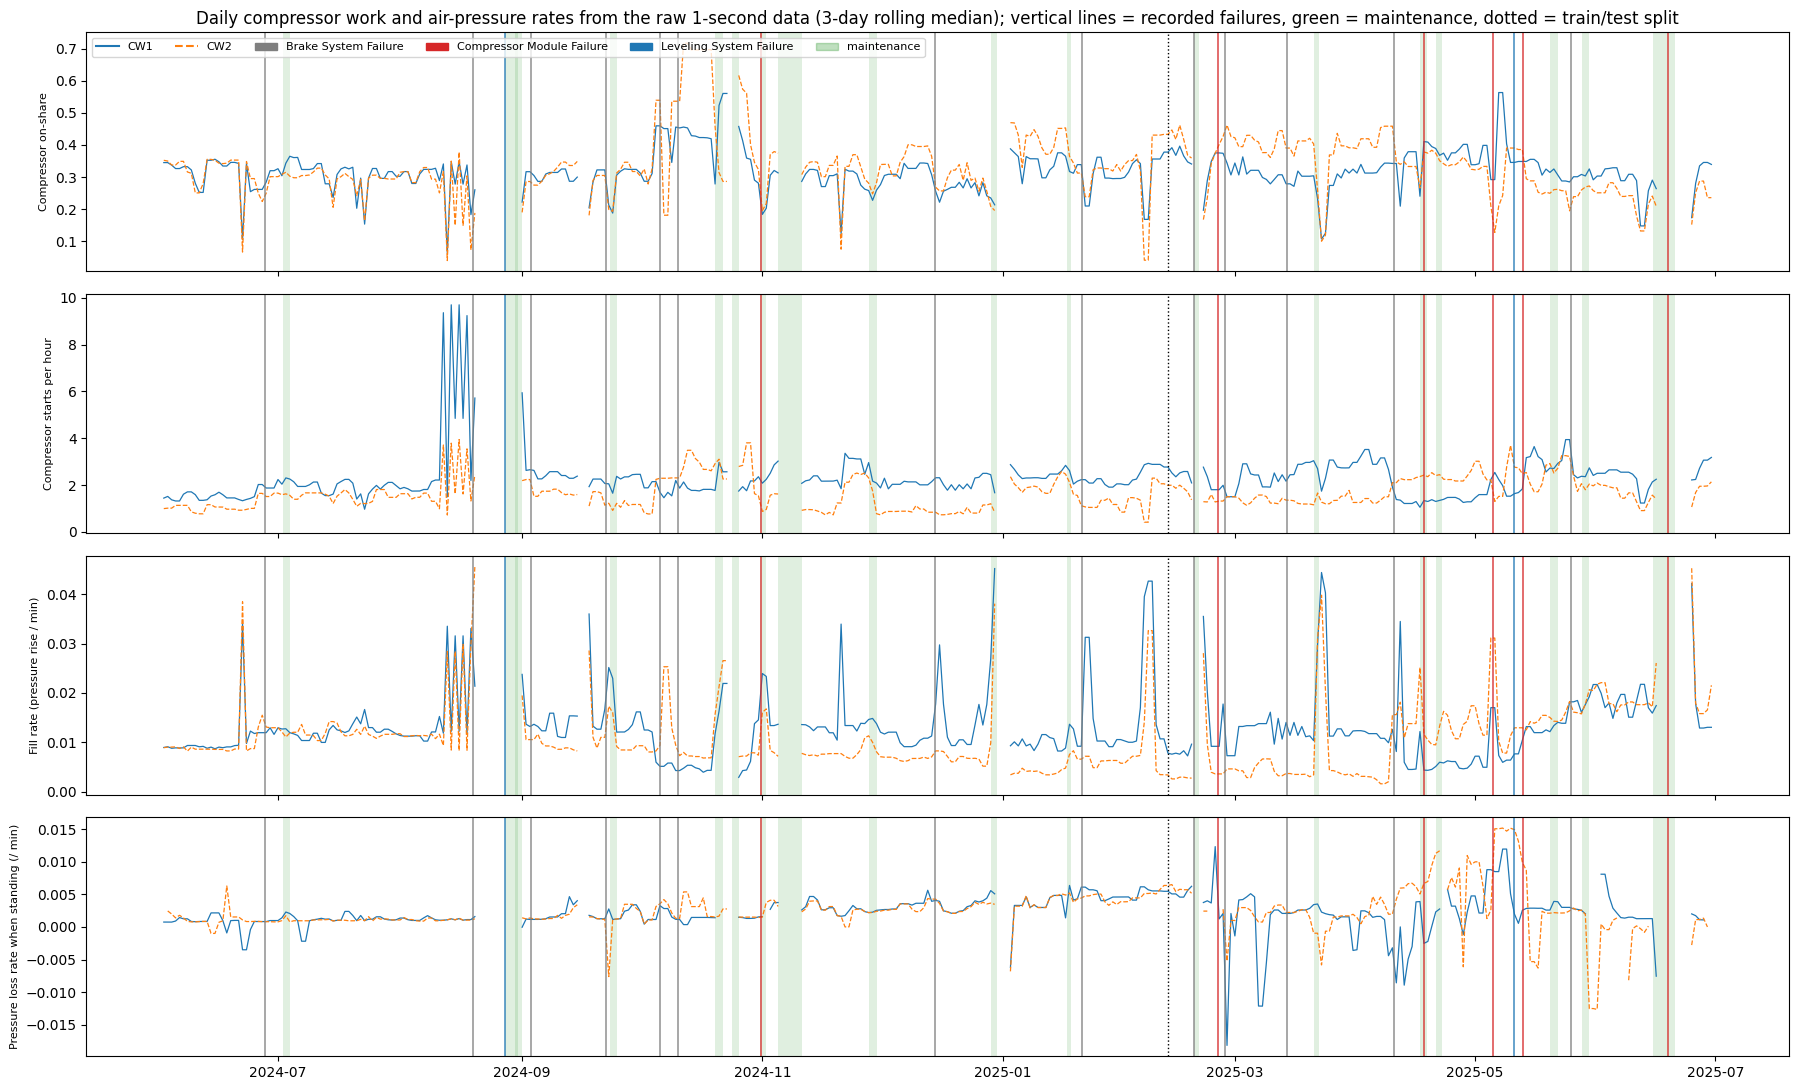

In [17]:
PHYS_COLS = ['TIMESTAMP', 'TRAIN_IS_IN_MAINTENANCE', 'TRAIN_SPEED_ACTUAL', 'CW1_COMPRESSOR_RUNNING', 'CW2_COMPRESSOR_RUNNING',
             'CW1_MAIN_RESERVOIR_PRESSURE', 'CW2_MAIN_RESERVOIR_PRESSURE']
STANDING = 0.01  # scaled speed below this = standing still
MAX_GAP_S = 5    # 2-3% of the raw steps skip a second; gaps up to 5 s still count as one uninterrupted period


def segment_slopes(t, p, state, keep):
    # Slope (per minute) of a straight-line fit for every uninterrupted run of seconds with the same compressor state
    brk = np.r_[True, (np.diff(t) > MAX_GAP_S) | (np.diff(state) != 0)]
    seg = np.cumsum(brk)
    d = pd.DataFrame({'seg': seg, 't': t - t[0], 'p': p, 'state': state, 'keep': keep})
    d['tp'], d['tt'] = d.t * d.p, d.t * d.t
    g = d.groupby('seg').agg(n=('t', 'size'), st=('t', 'sum'), sp=('p', 'sum'), stp=('tp', 'sum'), stt=('tt', 'sum'),
                             state=('state', 'first'), keep=('keep', 'all'))
    var = g.stt - g.st ** 2 / g.n
    g['slope_per_min'] = np.where(var > 0, (g.stp - g.st * g.sp / g.n) / var.where(var > 0, np.nan) * 60, np.nan)
    return g


def day_physics(f):
    df = pd.read_parquet(f, columns=PHYS_COLS)
    df['TIMESTAMP'] = pd.to_datetime(df['TIMESTAMP'])
    df = df.sort_values('TIMESTAMP').drop_duplicates('TIMESTAMP')  # raw day files are not stored in time order
    df = df[~df['TRAIN_IS_IN_MAINTENANCE'].astype(bool)].dropna()
    if len(df) < 600:
        return None
    t = df['TIMESTAMP'].values.astype('datetime64[s]').astype(np.int64)
    standing = (df['TRAIN_SPEED_ACTUAL'].values < STANDING)
    rec_h = len(df) / 3600
    row = {'date': df['TIMESTAMP'].iloc[0].normalize(), 'recorded_h': rec_h}
    for side in ('CW1', 'CW2'):
        on = df[f'{side}_COMPRESSOR_RUNNING'].values.astype(int)
        pres = df[f'{side}_MAIN_RESERVOIR_PRESSURE'].values.astype(float)
        starts = int(((np.diff(on) == 1) & (np.diff(t) <= MAX_GAP_S)).sum())
        g = segment_slopes(t, pres, on, standing)
        fill = g[(g.state == 1) & (g.n >= 30)].slope_per_min
        loss = -g[(g.state == 0) & g.keep & (g.n >= 60)].slope_per_min
        row.update({f'{side}_on_share': on.mean(), f'{side}_starts_per_h': starts / rec_h,
                    f'{side}_fill_rate': fill.median(), f'{side}_loss_rate': loss.median(),
                    f'{side}_n_fill': len(fill), f'{side}_n_loss': len(loss)})
    return row


PHYS_PATH = os.path.join(NB05_OUT, 'daily_physics.csv')
if os.path.exists(PHYS_PATH):
    daily_phys = pd.read_csv(PHYS_PATH, parse_dates=['date'])
    print(f'Loaded cached {PHYS_PATH} (delete it to recompute from the raw files)')
else:
    raw_files = sorted(_glob.glob(os.path.join(ROOT, 'train', '**', '*.parquet'), recursive=True) +
                       _glob.glob(os.path.join(ROOT, 'test', '**', '*.parquet'), recursive=True))
    daily_phys = pd.DataFrame([r for r in (day_physics(f) for f in raw_files) if r is not None])
    daily_phys = daily_phys.sort_values('date').reset_index(drop=True)
    daily_phys.to_csv(PHYS_PATH, index=False)
METRICS = {'on_share': 'Compressor on-share', 'starts_per_h': 'Compressor starts per hour',
           'fill_rate': 'Fill rate (pressure rise / min)', 'loss_rate': 'Pressure loss rate when standing (/ min)'}
for m in METRICS:
    daily_phys[m] = daily_phys[[f'CW1_{m}', f'CW2_{m}']].mean(axis=1)  # both sides together
daily_phys['split'] = np.where(daily_phys['date'] < SPLIT_DATE, 'train', 'test')
print(f'{len(daily_phys)} days with data; median recorded hours per day {daily_phys.recorded_h.median():.1f}')
print(daily_phys.groupby('split')[list(METRICS)].median().round(4).to_string())

# Maintenance periods from the raw flag (for the timeline and the trend analysis in 7.4b)
MAINT_PATH = os.path.join(NB05_OUT, 'maintenance_periods.csv')
if os.path.exists(MAINT_PATH):
    maint = pd.read_csv(MAINT_PATH, parse_dates=['start', 'end'])
else:
    mrows = []
    for f in sorted(_glob.glob(os.path.join(ROOT, 'train', '**', '*.parquet'), recursive=True) +
                    _glob.glob(os.path.join(ROOT, 'test', '**', '*.parquet'), recursive=True)):
        d = pd.read_parquet(f, columns=['TIMESTAMP', 'TRAIN_IS_IN_MAINTENANCE', 'TRAIN_MAINTENANCE_TYPE'])
        d = d[d['TRAIN_IS_IN_MAINTENANCE'].astype(bool)]
        if len(d):
            d['TIMESTAMP'] = pd.to_datetime(d['TIMESTAMP'])
            for typ, g in d.groupby('TRAIN_MAINTENANCE_TYPE'):
                mrows.append({'start': g.TIMESTAMP.min(), 'end': g.TIMESTAMP.max(), 'type': typ})
    maint = pd.DataFrame(mrows).sort_values('start')
    # merge pieces of the same maintenance type on consecutive days
    merged = []
    for r in maint.to_dict('records'):
        if merged and r['type'] == merged[-1]['type'] and r['start'] - merged[-1]['end'] < pd.Timedelta(days=2):
            merged[-1]['end'] = max(merged[-1]['end'], r['end'])
        else:
            merged.append(r)
    maint = pd.DataFrame(merged)
    maint.to_csv(MAINT_PATH, index=False)
print(f'{len(maint)} maintenance periods in the data:', ', '.join(f"{r.type} {r.start:%d %b %Y}" for r in maint.itertuples()))

type_col = {'Brake System Failure': '#7f7f7f', 'Compressor Module Failure': '#d62728', 'Leveling System Failure': '#1f77b4'}
fig, axes = plt.subplots(len(METRICS), 1, figsize=(18, 11), sharex=True)
for ax, (m, lab) in zip(axes, METRICS.items()):
    full = daily_phys.set_index('date').asfreq('D')  # days without data become gaps, not connecting lines
    for side, ls in (('CW1', '-'), ('CW2', '--')):
        ax.plot(full.index, full[f'{side}_{m}'].rolling(3, min_periods=2).median(), ls, lw=0.9, label=side)
    for r in maint.itertuples():
        ax.axvspan(r.start, r.end + pd.Timedelta(days=1), color='green', alpha=0.12, lw=0)
    for ev in fail_events.itertuples():
        ax.axvline(ev.start, color=type_col.get(ev.event_type, 'black'), lw=1.2, alpha=0.8)
    ax.axvline(SPLIT_DATE, color='black', ls=':', lw=1)
    ax.set_ylabel(lab, fontsize=8)
axes[0].legend(handles=[plt.Line2D([], [], color='C0', label='CW1'), plt.Line2D([], [], color='C1', ls='--', label='CW2')] +
               [Patch(color=c, label=t) for t, c in type_col.items()] + [Patch(color='green', alpha=0.25, label='maintenance')], ncol=6, fontsize=8, loc='upper left')
axes[0].set_title('Daily compressor work and air-pressure rates from the raw 1-second data (3-day rolling median); '
                  'vertical lines = recorded failures, green = maintenance, dotted = train/test split')
plt.tight_layout()
plt.savefig(os.path.join(NB05_OUT, 'daily_physics_timeline.png'), dpi=150, bbox_inches='tight')
plt.show()

### 7.4b Long-Term Trends: Gradual Change Over Months and the April 2025 Revision

The daily quantities change slowly over months, not in the days before single failures. Two observations, both **hypotheses for the experts** rather than conclusions:
- **Standing pressure loss** grows steadily over the training period. A growing leak would make the air system lose pressure faster when the compressor is off.
- **The CW2 side** fills more slowly and its compressor runs more from autumn 2024, until the **AJ revision of 17–18 April 2025**. Steiner et al. (RAMS 2026) report a baseline shift after 2025-04-17, the same date, so part of the test-period drift may be a repair or exchange during this revision.

Tests: Kendall's τ on the **monthly** medians of the training period (daily values are strongly autocorrelated, so a test on single days would overstate the evidence), and a Mann–Whitney test of the 30 days before vs the 30 days after the April revision (days are not independent either, so the p-value is indicative only).

In [18]:
from scipy.stats import kendalltau, mannwhitneyu

monthly = daily_phys.set_index('date').resample('MS')[
    ['loss_rate', 'CW1_fill_rate', 'CW2_fill_rate', 'CW1_on_share', 'CW2_on_share', 'CW1_starts_per_h', 'CW2_starts_per_h']].median()
print('Monthly medians:')
print(monthly.round(4).to_string())

train_m = monthly[monthly.index < SPLIT_DATE]
print('\nTrend over the training period (Kendall tau on monthly medians):')
trend_rows = []
for col in ['loss_rate', 'CW1_fill_rate', 'CW2_fill_rate', 'CW1_on_share', 'CW2_on_share']:
    v = train_m[col].dropna()
    tau, p_tau = kendalltau(np.arange(len(v)), v.values)
    trend_rows.append({'quantity': col, 'months': len(v), 'first': v.iloc[0], 'last': v.iloc[-1], 'tau': tau, 'p': p_tau})
trend_tab = pd.DataFrame(trend_rows)
print(trend_tab.round({'first': 4, 'last': 4, 'tau': 2, 'p': 4}).to_string(index=False))

rev = maint[(maint.start >= '2025-04-10') & (maint.start <= '2025-04-25')].sort_values('start')
if len(rev):
    r0, r1 = rev.start.min().normalize(), rev.end.max().normalize() + pd.Timedelta(days=1)
    before = daily_phys[daily_phys.date.between(r0 - pd.Timedelta(days=30), r0 - pd.Timedelta(days=1))]
    after = daily_phys[daily_phys.date.between(r1, r1 + pd.Timedelta(days=29))]
    print(f'\nApril 2025 revision ({", ".join(rev.type.astype(str))}, {r0:%d %b} - {r1:%d %b}): 30 days before vs 30 days after')
    rev_rows = []
    for col in ['CW1_fill_rate', 'CW2_fill_rate', 'CW1_on_share', 'CW2_on_share', 'loss_rate']:
        b, a = before[col].dropna(), after[col].dropna()
        rev_rows.append({'quantity': col, 'median before': b.median(), 'median after': a.median(),
                         'p (Mann-Whitney)': mannwhitneyu(b, a).pvalue if len(b) and len(a) else np.nan})
    rev_tab = pd.DataFrame(rev_rows)
    print(rev_tab.round(4).to_string(index=False))
trend_tab.to_csv(os.path.join(NB05_OUT, 'long_term_trends.csv'), index=False)

Monthly medians:
            loss_rate  CW1_fill_rate  CW2_fill_rate  CW1_on_share  CW2_on_share  CW1_starts_per_h  CW2_starts_per_h
date                                                                                                               
2024-06-01     0.0009         0.0094         0.0088        0.3295        0.3257            1.5156            1.0327
2024-07-01     0.0011         0.0121         0.0117        0.3203        0.2996            1.9795            1.5417
2024-08-01     0.0011         0.0121         0.0114        0.3171        0.2936            2.0501            1.4744
2024-09-01     0.0013         0.0133         0.0093        0.3144        0.3121            2.4059            1.5676
2024-10-01     0.0016         0.0054         0.0079        0.4223        0.5392            1.8690            2.6671
2024-11-01     0.0026         0.0134         0.0077        0.3052        0.3349            2.3092            1.1428
2024-12-01     0.0030         0.0110         0.0068    

### 7.5 Average Profile Around Failures (supervisor feedback: "how do the values change before a failure")

All failures of one recorded type are aligned at their onset day (day 0), and each daily quantity is followed from 14 days before to 3 days after. To remove the difference between periods (drift) and between events, every event is measured **relative to its own baseline**, the median of its days −14 to −8. The thick line is the mean change over the events of that type, the band a 95% bootstrap interval over events, the thin lines the single events.

The table tests whether the last three days before onset (−3 to −1) differ from the baseline days (−14 to −8), with a Wilcoxon signed-rank test over the events of each type and a Benjamini–Hochberg correction across all tests. Leveling (2 events) is shown but not tested. Failures that follow each other closely (e.g. 18, 24 and 26 Feb 2025) share baseline days, which is a limitation of so few events.

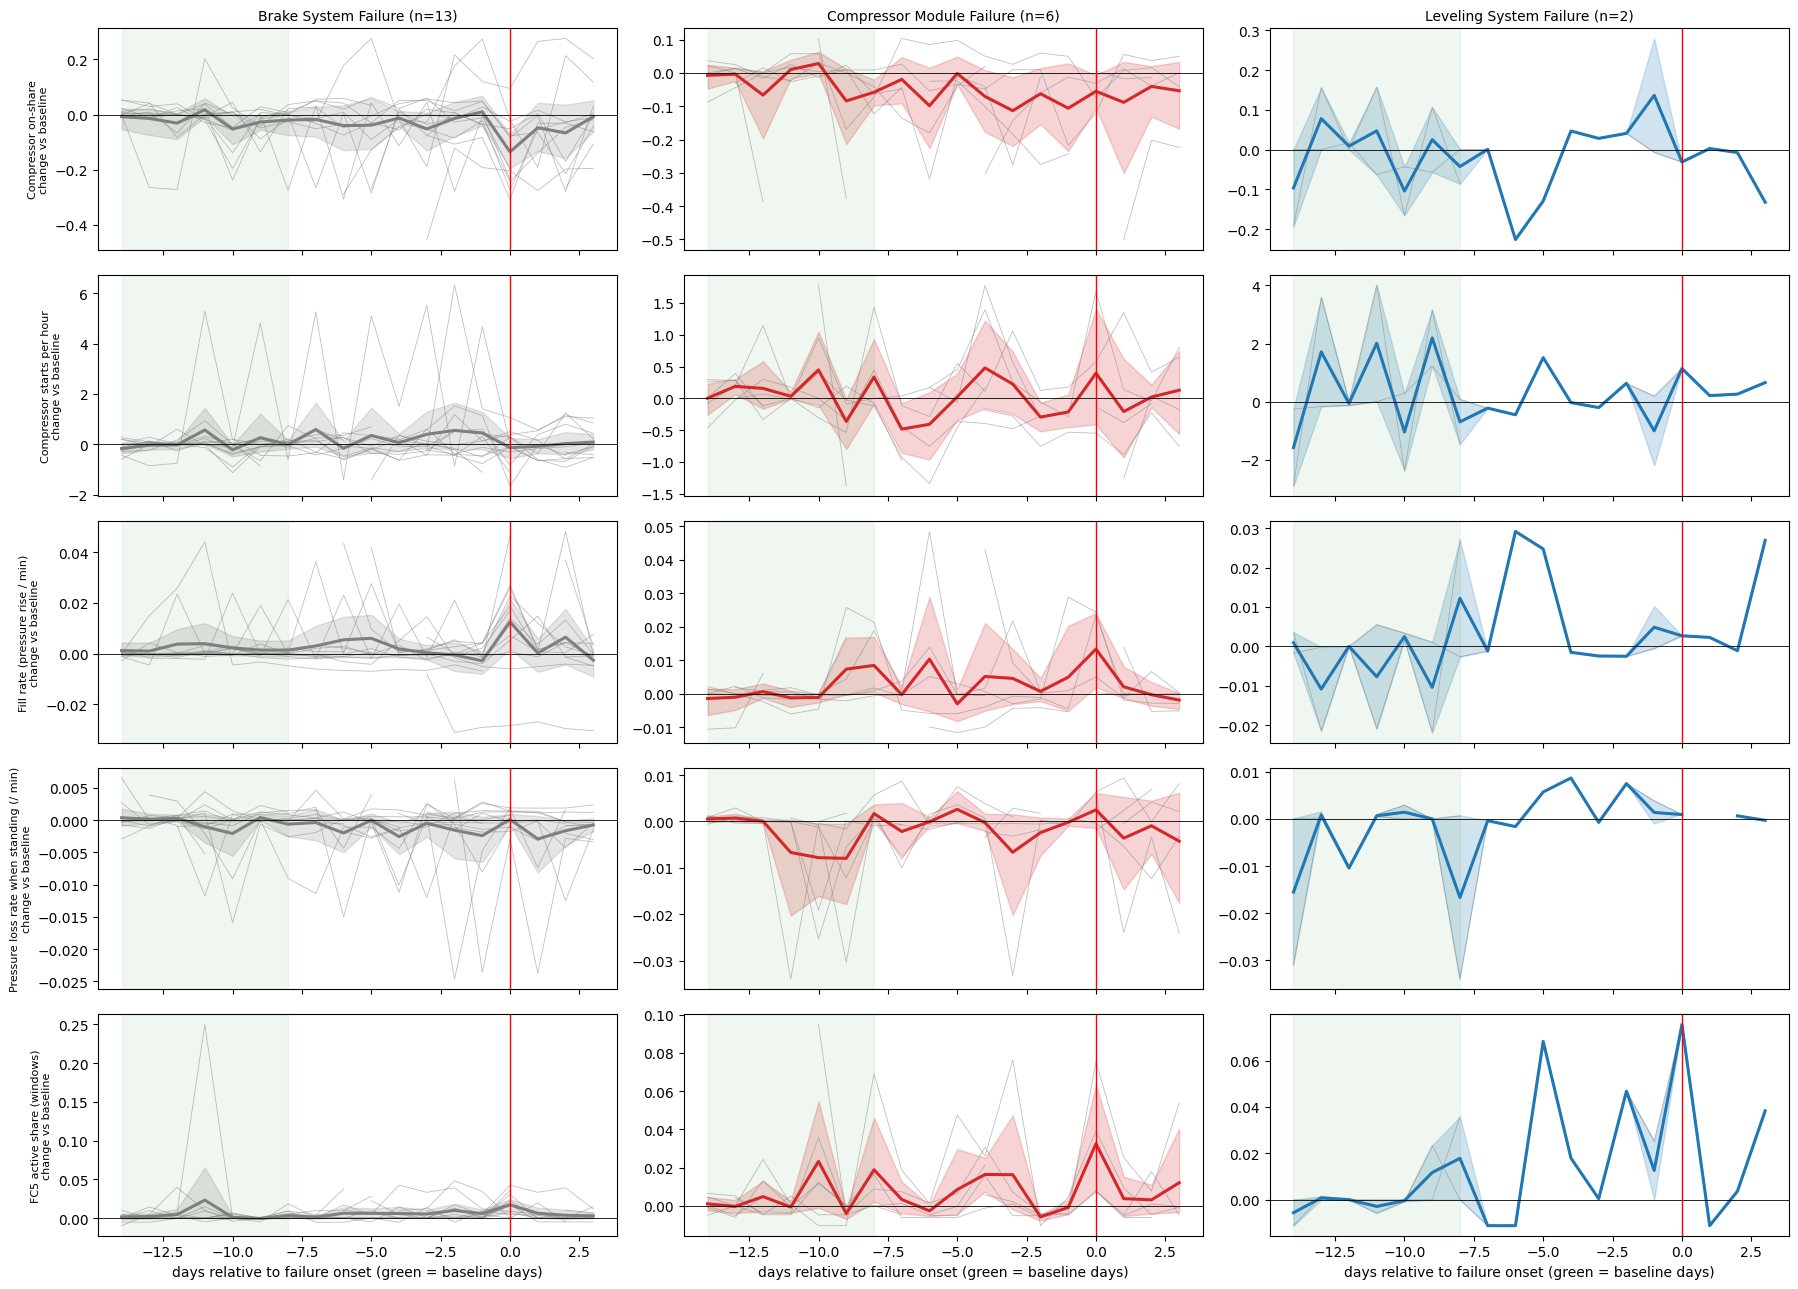

             failure type                                 quantity  events  median change (days -3..-1)     p  q (BH)
     Brake System Failure                      Compressor on-share      13                      -0.0030 0.635   0.685
     Brake System Failure               Compressor starts per hour      13                       0.0784 0.414   0.547
     Brake System Failure          Fill rate (pressure rise / min)      13                       0.0007 0.685   0.685
     Brake System Failure Pressure loss rate when standing (/ min)      13                      -0.0004 0.340   0.547
     Brake System Failure               FC5 active share (windows)      13                       0.0031 0.005   0.051
Compressor Module Failure                      Compressor on-share       6                      -0.0846 0.062   0.312
Compressor Module Failure               Compressor starts per hour       6                      -0.2048 0.312   0.547
Compressor Module Failure          Fill rate (pressure r

In [19]:
from scipy.stats import wilcoxon

PROFILE = list(METRICS) + ['fc5_share']
fc5_daily = (fc_act_all[5].groupby(all_sup['window_end'].dt.normalize()).mean() if 5 in fc_act_all else pd.Series(dtype=float))
dp = daily_phys.set_index('date')
dp['fc5_share'] = fc5_daily.reindex(dp.index)
labels = dict(METRICS, fc5_share='FC5 active share (windows)')
offsets = np.arange(-14, 4)

profiles = []  # one row per event, metric and day offset: change against the event's own baseline
for ev_id, ev in fail_events.iterrows():
    onset_day = ev.start.normalize()
    days = onset_day + pd.to_timedelta(offsets, unit='D')
    vals = dp.reindex(days)[PROFILE]
    base = vals.iloc[:7].median()  # days -14 .. -8
    for m in PROFILE:
        for off, v in zip(offsets, vals[m].values):
            profiles.append({'event': ev_id, 'type': ev.event_type, 'metric': m, 'offset': off, 'change': v - base[m]})
profiles = pd.DataFrame(profiles)

rng = np.random.RandomState(0)
types = fail_events.event_type.value_counts().index.tolist()
fig, axes = plt.subplots(len(PROFILE), len(types), figsize=(6 * len(types), 2.6 * len(PROFILE)), sharex=True, squeeze=False)
for j, ty in enumerate(types):
    for i, m in enumerate(PROFILE):
        ax = axes[i, j]
        sub = profiles[(profiles.type == ty) & (profiles.metric == m)].pivot(index='event', columns='offset', values='change')
        for _, r in sub.iterrows():
            ax.plot(offsets, r.values, color='grey', lw=0.6, alpha=0.5)
        mean = sub.mean()
        boot = np.array([sub.iloc[rng.randint(0, len(sub), len(sub))].mean().values for _ in range(1000)])
        lo, hi = np.nanpercentile(boot, 2.5, axis=0), np.nanpercentile(boot, 97.5, axis=0)
        ax.fill_between(offsets, lo, hi, color=type_col.get(ty, 'C0'), alpha=0.2)
        ax.plot(offsets, mean.values, color=type_col.get(ty, 'C0'), lw=2.2)
        ax.axhline(0, color='black', lw=0.6); ax.axvline(0, color='red', lw=1)
        ax.axvspan(-14, -8, color='green', alpha=0.06)
        if i == 0:
            ax.set_title(f'{ty} (n={len(sub)})', fontsize=10)
        if j == 0:
            ax.set_ylabel(labels[m] + '\nchange vs baseline', fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel('days relative to failure onset (green = baseline days)')
plt.tight_layout()
plt.savefig(os.path.join(NB05_OUT, 'failure_profiles.png'), dpi=150, bbox_inches='tight')
plt.show()

rows = []
for ty in types:
    for m in PROFILE:
        sub = profiles[(profiles.type == ty) & (profiles.metric == m)]
        last3 = sub[sub.offset.between(-3, -1)].groupby('event').change.mean().dropna()
        n = len(last3)
        stat_p = wilcoxon(last3).pvalue if n >= 5 and (last3 != 0).any() else np.nan
        rows.append({'failure type': ty, 'quantity': labels[m], 'events': n, 'median change (days -3..-1)': last3.median(), 'p': stat_p})
tests = pd.DataFrame(rows)
pv = tests['p'].dropna().sort_values()
bh = (pv * len(pv) / np.arange(1, len(pv) + 1))[::-1].cummin()[::-1].clip(upper=1)  # Benjamini-Hochberg
tests['q (BH)'] = bh.reindex(tests.index)
tests.to_csv(os.path.join(NB05_OUT, 'failure_profile_tests.csv'), index=False)
print(tests.round({'median change (days -3..-1)': 4, 'p': 3, 'q (BH)': 3}).to_string(index=False))

## 8. Expert Verification Sheet and RQ1 Verification Metric

The sheet has one row per FC with all evidence from NB04/NB05, plus empty columns for the Wiener Linien experts:

| Column | Expected entry |
|---|---|
| `expert_physically_coherent` | Y / N: do these sensors belong together physically? |
| `expert_subsystem` | e.g. Brake, APU, Leveling, other, unclear |
| `expert_failure_mode` | free text: known failure mode this pattern indicates |
| `expert_keep` | Y / N: use the FC in the subsystem datasets for RQ2? |
| `expert_comment` | free text |

**RQ1 verification metric** (proposal §4: "the degree to which the constructed subsystem structures are verified by domain experts"), computed from the returned sheet:
- **FC confirmation rate:** share of FCs marked physically coherent, by count and by number of features.
- **Assignment rate:** share of confirmed FCs that received a subsystem.
- **Retention rate:** share of features kept for RQ2.

Once the sheet is filled in, `build_subsystem_datasets()` writes one dataset per expert-assigned subsystem with identical windows, labels and split (exposé p.10: identical experimental conditions for RQ2).

In [20]:
EXPERT_COLS = ['expert_physically_coherent', 'expert_subsystem', 'expert_failure_mode', 'expert_keep', 'expert_comment']
type_share = type_tab.astype(float).round(1)
sheet = (fc_summary[['FC', 'n_features', 'n_sensors', 'activation_rate', 'failure_rate']]
         .merge(fc_location[['FC', 'cars', 'side_A_share', 'side_B_share', 'bogies', 'signal_types']], on='FC')
         .merge(fc_scores[['FC', 'early_hits', 'late_hits', 'events_covered', 'false_alarms', 'fa_per_30_normal_days',
                           'lift', 'median_lead_h', 'pattern', 'drift_flag', 'lift_train', 'verdict', 'lift_test',
                           'test_check']], on='FC'))
sheet['failure_type_enrichment'] = [', '.join(f'{c.split(" (")[0]}: {v}x' for c, v in type_share.loc[fc].items()) for fc in sheet['FC']]
sheet['rf_false_alarm_marker'] = sheet['FC'].map(enrich_tables['RF'].set_index('FC')['characterises'])
sheet['features'] = sheet['FC'].map(lambda f: '; '.join(sorted(clusters[int(f[2:])])))
sheet['deep_dive_plot'] = sheet['FC'].map(lambda f: f'nb05_artifacts/fc{f[2:]}_deep_dive.png' if int(f[2:]) in picks else '')
for c in EXPERT_COLS:
    sheet[c] = ''
sheet = sheet.round(3)

sheet_csv = os.path.join(NB05_OUT, 'expert_verification_sheet.csv')
filled_path = os.path.join(NB05_OUT, 'expert_verification_sheet_FILLED.csv')
sheet.to_csv(sheet_csv, index=False)
try:
    sheet.to_excel(os.path.join(NB05_OUT, 'expert_verification_sheet.xlsx'), index=False)
    print('Saved expert_verification_sheet.csv and .xlsx')
except ImportError:
    print('Saved expert_verification_sheet.csv (install openpyxl for an .xlsx copy)')
print(f'{len(sheet)} rows; experts return it as {os.path.basename(filled_path)}')
display(sheet.drop(columns=['features']).head(10))

Saved expert_verification_sheet.csv and .xlsx
19 rows; experts return it as expert_verification_sheet_FILLED.csv


,FC,n_features,n_sensors,activation_rate,failure_rate,cars,side_A_share,side_B_share,bogies,signal_types,...,lift_test,test_check,failure_type_enrichment,rf_false_alarm_marker,deep_dive_plot,expert_physically_coherent,expert_subsystem,expert_failure_mode,expert_keep,expert_comment
0,FC1,12,12,0.232,0.048,"CW1, CW2, MW1, MW2, MW3, MW4",0.50,0.50,"B1, B2",BRAKE_CYLINDER_PRESSURE,...,1.181,fails,"Brake System Failure: 1.6x, Compressor Module ...",early hits,,,,,,
1,FC2,1,1,0.326,0.101,MW4,0.00,1.00,-,LOAD_SIGNAL,...,1.087,fails,"Brake System Failure: 3.2x, Compressor Module ...",false alarms,,,,,,
2,FC3,4,4,0.056,0.106,"CW1, CW2",0.50,0.50,"B1, B2",SPRING_BRAKE_ACTIVE,...,1.047,fails,"Brake System Failure: 3.2x, Compressor Module ...",,,,,,,
3,FC4,1,1,0.041,0.078,CW1,1.00,0.00,-,COMPRESSOR_RUNNING,...,0.817,fails,"Brake System Failure: 2.6x, Compressor Module ...",,,,,,,
4,FC5,1,1,0.029,0.154,CW2,0.00,1.00,-,COMPRESSOR_RUNNING,...,1.922,holds,"Brake System Failure: 4.2x, Compressor Module ...",,,,,,,
5,FC6,19,10,0.097,0.220,"CW1, CW2, MW1, MW2, MW3, MW4",0.53,0.47,"B1, B2",SPRING_BRAKE_PRESSURE,...,1.224,fails,"Brake System Failure: 6.5x, Compressor Module ...",false alarms,,,,,,
6,FC7,2,2,0.011,0.627,CW1,1.00,0.00,B2,"LOAD_PRESSURE, SPRING_BRAKE_PRESSURE",...,2.384,holds,"Brake System Failure: 62.2x, Compressor Module...",,nb05_artifacts/fc7_deep_dive.png,,,,,
7,FC8,7,7,0.023,0.339,"CW2, MW1, MW2, MW3, MW4",0.43,0.57,"B1, B2",SPRING_BRAKE_PRESSURE,...,1.542,holds,"Brake System Failure: 11.6x, Compressor Module...",,nb05_artifacts/fc8_deep_dive.png,,,,,
8,FC9,4,4,0.066,0.126,MW1,1.00,0.00,B2,"LOAD_PRESSURE, PNEUMATIC_BRAKING_FORCE, PROPOR...",...,1.242,fails,"Brake System Failure: 3.8x, Compressor Module ...",,,,,,,
9,FC10,16,16,0.174,0.063,"CW1, CW2, MW1, MW2, MW3, MW4",0.50,0.50,"B1, B2","PNEUMATIC_BRAKING_FORCE, PROPORTIONAL_VALVE_PR...",...,1.012,fails,"Brake System Failure: 2.7x, Compressor Module ...",,,,,,,


In [21]:
def verification_metrics(filled):
    yes = lambda s: s.astype(str).str.strip().str.upper().isin(['Y', 'YES', 'J', 'JA'])
    conf = yes(filled['expert_physically_coherent'])
    assigned = conf & filled['expert_subsystem'].astype(str).str.strip().ne('') & filled['expert_subsystem'].notna()
    keep = yes(filled['expert_keep'])
    return {
        'fc_confirmation_rate': conf.mean(),
        'feature_confirmation_rate': filled.loc[conf, 'n_features'].sum() / filled['n_features'].sum(),
        'assignment_rate_among_confirmed': assigned.sum() / max(conf.sum(), 1),
        'feature_retention_rate': filled.loc[keep, 'n_features'].sum() / filled['n_features'].sum(),
    }


def build_subsystem_datasets(filled, out_dir=os.path.join(OUT, 'subsystem_datasets')):
    os.makedirs(out_dir, exist_ok=True)
    yes = lambda s: s.astype(str).str.strip().str.upper().isin(['Y', 'YES', 'J', 'JA'])
    use = filled[yes(filled['expert_keep']) & filled['expert_subsystem'].notna() &
                 filled['expert_subsystem'].astype(str).str.strip().ne('')]
    meta_cols = ['window_end', 'label', 'split']
    summary = {}
    for sub, grp in use.groupby(use['expert_subsystem'].astype(str).str.strip()):
        feats = sorted({f for fc in grp['FC'] for f in clusters[int(fc[2:])]})
        name = sub.lower().replace(' ', '_')
        all_sup[meta_cols + feats].to_parquet(os.path.join(out_dir, f'{name}.parquet'))
        summary[sub] = {'fcs': list(grp['FC']), 'n_features': len(feats)}
    with open(os.path.join(out_dir, 'subsystem_datasets.json'), 'w') as f:
        json.dump(summary, f, indent=2)
    return summary


if os.path.exists(filled_path):
    filled = pd.read_csv(filled_path)
    print('RQ1 verification metrics:', {k: round(v, 3) for k, v in verification_metrics(filled).items()})
    print('Subsystem datasets:', build_subsystem_datasets(filled))
else:
    print(f'Awaiting expert input: place the completed sheet at {filled_path} and re-run this cell.')

Awaiting expert input: place the completed sheet at C:\Users\Emırhan\Desktop\MASTER THESIS\Kurtulus-thesis\outputs\nb05_artifacts\expert_verification_sheet_FILLED.csv and re-run this cell.


## 9. Summary for the Expert Meeting

All numbers below are computed in this run. Observations are not conclusions; the experts decide.

In [22]:
print('=' * 90)
print('ANOMALY PATTERN DISCOVERY: SUMMARY FOR EXPERT VERIFICATION')
print('=' * 90)
print(f'Windows: {len(all_sup):,} | anomalous: {len(anom_activations):,} ({len(anom_activations) / len(all_sup):.1%})')
print(f'Feature clusters: {len(clusters)} ({sum(len(v) for v in clusters.values())} features)')
print(f'Failure events: {len(fail_events)} (train {(fail_events.split == "train").sum()}, test {(fail_events.split == "test").sum()}); '
      f'types {fail_events.event_type.value_counts().to_dict()}')

print('\n--- Temporal patterns (NB04 §4.3) ---')
for pat in ('early-warning', 'short-term precursor', 'detection-only', 'weak / mixed', 'background'):
    fcs = fc_temporal.loc[fc_temporal.pattern == pat, 'FC'].tolist()
    print(f'{pat:15s} ({len(fcs):2d}): {", ".join(fcs)}')

print('\n--- Volatility before onset (NB04 §4.5) ---')
for r in fc_variance.itertuples():
    print(f'{r.FC}: pre-onset volatility {r.pre_vol_ratio:.2f}x baseline, day-0 {r.day0_vol_ratio:.2f}x -> {r.interpretation}')

print('\n--- Event-level scorecard (§3) ---')
print('Verdict on the 10 train events; test check on the 11 test events')
for r in fc_scores[fc_scores.verdict == 'KEEP'].sort_values('lift_train', ascending=False).itertuples():
    print(f'KEEP {r.FC}: train lift {r.lift_train:.2f} ({r.events_covered_train} train events), test check {r.test_check} '
          f'(test lift {r.lift_test:.2f}, {r.events_covered_test} test events); all events: covered {r.events_covered}/{n_ev} (early {r.early_hits}), '
          f'false alarms {r.false_alarms}, median lead {r.median_lead_h:.1f} h{" [drift]" if r.drift_flag else ""}')
print(f'REVIEW: {", ".join(fc_scores.loc[fc_scores.verdict == "REVIEW", "FC"])}')

print('\n--- Prior-work flagged intervals (§4) ---')
for name, t in enrich_tables.items():
    sig = t[t.characterises != '']
    print(f'{name}: ' + (', '.join(sig.FC + ' -> ' + sig.characterises) if len(sig) else 'no FC significantly separates early hits from false alarms'))

drift = fc_drift.loc[fc_drift.drift_flag, 'FC'].tolist()
print(f'\n--- Drift (NB04 §4.6): {", ".join(drift) or "none"} ---')

print('\n--- Questions for the experts ---')
print('Q1: Do the sensors in each FC belong together physically (see sheet, column features / signal_types)?')
print('Q2: Which subsystem does each FC belong to?')
print('Q3: Which FCs correspond to known failure modes (see failure-type table, §5)?')
print('Q4: Are FCs that characterise false alarms (§4) normal operating patterns, e.g. braking manoeuvres?')
print('Q5: Which FCs should be kept for the subsystem datasets of RQ2?')

ANOMALY PATTERN DISCOVERY: SUMMARY FOR EXPERT VERIFICATION
Windows: 64,522 | anomalous: 12,022 (18.6%)
Feature clusters: 19 (126 features)
Failure events: 21 (train 10, test 11); types {'Brake System Failure': 13, 'Compressor Module Failure': 6, 'Leveling System Failure': 2}

--- Temporal patterns (NB04 §4.3) ---
early-warning   ( 0): 
short-term precursor ( 2): FC5, FC7
detection-only  (12): FC1, FC3, FC4, FC6, FC8, FC9, FC12, FC13, FC14, FC16, FC17, FC18
weak / mixed    ( 5): FC2, FC10, FC11, FC15, FC19
background      ( 0): 

--- Volatility before onset (NB04 §4.5) ---
FC2: pre-onset volatility 1.18x baseline, day-0 1.55x -> increase only at onset day (sudden)
FC5: pre-onset volatility 1.14x baseline, day-0 1.28x -> no volatility change
FC6: pre-onset volatility 1.05x baseline, day-0 1.44x -> no volatility change
FC7: pre-onset volatility 1.03x baseline, day-0 1.15x -> no volatility change
FC8: pre-onset volatility 0.99x baseline, day-0 1.01x -> no volatility change
FC18: pre-onset 

In [23]:
fc_summary.to_csv(os.path.join(NB05_OUT, 'fc_summary.csv'), index=False)
fc_scores.to_csv(os.path.join(NB05_OUT, 'fc_scorecard.csv'), index=False)
type_tab.astype(float).round(2).to_csv(os.path.join(NB05_OUT, 'fc_failure_type.csv'))
for name, t in enrich_tables.items():
    t.to_csv(os.path.join(NB05_OUT, f'prior_{name.lower().replace("-", "")}_fc_enrichment.csv'), index=False)
pd.concat({n: e.drop(columns=['early_events', 'late_events']) for n, e in model_eps.items()}).to_csv(
    os.path.join(NB05_OUT, 'prior_model_alarm_episodes.csv'))
with open(os.path.join(NB05_OUT, 'fc_sensor_lists.json'), 'w') as f:
    json.dump({str(fc): sorted(clusters[fc]) for fc in fc_ids}, f, indent=2)

for stale in ('fc_failure_mapping.csv', 'anom_meta_enriched.parquet', 'fail_events.parquet', 'fc_subsystem_map.png',
              'subsystem_feature_groups.json'):
    p = os.path.join(NB05_OUT, stale)
    if os.path.exists(p):
        os.remove(p)

print(f'Saved NB05 artifacts to {NB05_OUT}:')
for f in sorted(os.listdir(NB05_OUT)):
    print(f'  {f}: {os.path.getsize(os.path.join(NB05_OUT, f)):,} bytes')

Saved NB05 artifacts to C:\Users\Emırhan\Desktop\MASTER THESIS\Kurtulus-thesis\outputs\nb05_artifacts:
  daily_physics.csv: 70,345 bytes
  daily_physics_timeline.png: 507,191 bytes
  expert_verification_sheet.csv: 9,829 bytes
  expert_verification_sheet.xlsx: 9,285 bytes
  failure_profile_tests.csv: 1,470 bytes
  failure_profiles.png: 1,002,747 bytes
  fc5_raw_signals.png: 46,486 bytes
  fc7_deep_dive.png: 430,456 bytes
  fc7_raw_signals.png: 124,921 bytes
  fc8_deep_dive.png: 1,060,382 bytes
  fc8_raw_signals.png: 198,059 bytes
  fc_failure_type.csv: 483 bytes
  fc_failure_type.png: 124,879 bytes
  fc_overview.png: 74,329 bytes
  fc_scorecard.csv: 3,772 bytes
  fc_scorecard.png: 97,742 bytes
  fc_sensor_lists.json: 5,647 bytes
  fc_summary.csv: 2,539 bytes
  fc_timeline.png: 255,473 bytes
  fc_top10_features.csv: 15,657 bytes
  long_term_trends.csv: 500 bytes
  maintenance_periods.csv: 1,068 bytes
  prior_lstmae_fc_enrichment.csv: 1,549 bytes
  prior_model_alarm_episodes.csv: 36,798 b

## Traceability: Pipeline Position

**NB01 > NB02a > NB02b > NB03 > NB04 > NB05**

### What this notebook provides
- Event-level scorecard per FC: early hits, late hits, false-alarm episodes (with persistence filter), lift, lead time, KEEP/REVIEW decided on the train events with a test-event check
- FC activity behind the RF / LSTM-AE flagged intervals: early hits vs false alarms (RAMS 2026 pipeline)
- FC activity per failure type recorded by Wiener Linien (evidence only, no subsystem labels)
- Expert verification sheet, RQ1 verification metric, and code that builds the RQ2 subsystem datasets from the filled sheet

### Outputs (`outputs/nb05_artifacts/`)
- `expert_verification_sheet.csv` / `.xlsx`
- `fc_scorecard.csv`, `fc_summary.csv`, `fc_failure_type.csv`, `fc_sensor_lists.json`
- `prior_rf_fc_enrichment.csv`, `prior_lstmae_fc_enrichment.csv`, `prior_model_alarm_episodes.csv`
- `fc_top10_features.csv` (top-10 features per FC with values), `rf_importance_by_fc.csv`
- `daily_physics.csv` (daily compressor work and air-pressure rates from the raw data), `failure_profile_tests.csv`, `long_term_trends.csv`, `maintenance_periods.csv`
- Plots: `daily_physics_timeline.png`, `failure_profiles.png`
- Plots: `fc*_raw_signals.png` (raw 1-second signals), `rf_importance_by_fc.png`, `fc_overview.png`, `fc_scorecard.png`, `prior_model_fc_enrichment.png`, `fc_failure_type.png`, `fc_timeline.png`, `fc*_deep_dive.png`